# 03c Tuning room: the own-face patch on a held-out room (issue #20), re-checked on the per-element-patch logic (issue #23)

**Why this notebook exists.** The Phase 0.5 gate fails on room B (`03a`, `03b`, `05b`). Room B is the gate's own slice, so 03a's method must not be tuned there (owner's decision, #20). It is tuned on **held-out rooms of the CRAS lab**, and room B is re-run once afterwards. There are two tuning rooms, one notebook each with the same code: `03c_tuning_room.ipynb` (the south part of the west hall) and `03c_tuning_room_a.ipynb` (room A). **This notebook is the south part of the west hall.** Phase 1 (baseline, proxy, diagnosis, known answers) found that the label-free verdicts lose points that are not on the element's face at all; phase 2 implements the one change the owner chose, **the own-face patch**, and tunes its two judgement calls on the two held-out rooms only. The thresholds are fixed and untouched: `TOL` 15 mm (USIBD LOA30) and `MIN_FRAC_OK` 0.95 (LOA30's confidence level).

**This version.** #20 tuned the patch on 03a's logic as it was before #23 (the scan cropped to the room box, a sliver rule). 03a now judges each element on its **element patch**. This notebook uses that logic (imported from `scan_vs_bim.compare`) and re-checks the patch on it with **#20's parameters unchanged and no re-tuning**, against an acceptance rule fixed in advance (section 8). Room B is never used. The patch goes into 03a and 03b only if it passes on both held-out rooms.

**The room.** The south part of the west hall of the lab (`03c_tuning_slice.json`, written by `scripts/make_tuning_slice.py`: box x -9.93 to -2.70 m, y -0.95 to 8.80 m, 30 elements, 3.2 M scan points). It shares no wall and no box face with room B; the two elements it lists that room B also lists (the building-wide floor slab and one ceiling covering) are excluded from scoring.

**How 03a's logic runs on it.** 03a is hard-wired to room B and is the gate notebook. This notebook **imports 03a's logic as it is since #23** from `scan_vs_bim.compare` (it carried a copy of it until #41): all 135 element-class elements of the model are tessellated, the room's elements are in scope and the rest are neighbours; each element in scope is judged on its element patch (the scan points within `BAND` of its whole surface for which it is the nearest of the 135 elements; the room box only selects the scope; there is no sliver rule; an element with no point reads 'not confirmed, no points'), and the own-face patch (section 7) goes on top. `SLICE_JSON` selects the slice (this room by default; `01_cras_slice.json` runs room B, where this notebook's run with the patch **on** (03a runs with it since #20, with the same parameters) must reproduce 03a's CSVs row for row, asserted in the report cell and by `tests/test_notebook_03c.py`). Two things differ from 03a as it was until issue #31, neither of which changes a verdict on room B, and 03a has both now: a wall with no scan point in its patch is skipped (the guard), and the verdict cloud is selected **after** the ICP correction instead of before it (`patch_cloud`, section 2; 03a streams the cache a second time after its correction). The second one mattered here: the west hall's correction turns the room by 0.37 degrees, which moves the far corners of the building-wide floor slab by 128 mm, past the 5 cm slack in 03a's old prefilter (its assertion would have failed; that is issue #31). The proxy's "every other element" is every other element of the model, as in 03a's junction margin.

**What it does.** (1) 03a's verdict table on this room, without and with oracle labels (the patch off). (2) A **proxy for the hand check**: per element a truth that does not use the verdict rule. (3) A **diagnosis** of why the label-free shares fall below 95 %. (4) The label-free **frame** against the oracle-point frame. (5) **The own-face patch** per element, with #20's judgement calls (the edge allowance, the element classes, one-sided walls) and a sweep over them as context. (6) **Known answers** by perturbation, 03b's way, with and without the patch, and (7) **the acceptance rule** applied to (5) and (6). **Elements that room B's element list also holds are kept in the room (their points must be assigned to something) but are never scored or tuned on**; `scoring_exclusions` in the slice JSON lists them.

Terms are defined in [CONTEXT.md](../CONTEXT.md). All randomness is seeded. Nothing is written outside `outputs/` (gitignored).

## 1. Parameters and load

03a's parameters (post-#23), unchanged (the constants of the verdict rules are `scan_vs_bim.compare.RULES`, with their reasons; the others keep their justification comments, as in 03b), then the contract from the slice JSON, all 135 element-class elements tessellated with `only_guids` (the room's in scope, the others neighbours), and the scan cache streamed once for the ICP crop, the box padded by `PAD` (03a section 1). The slice JSON has 01's schema and 01's recorded transform (the lab's, reused unchanged).

In [1]:
import csv, dataclasses, json, os, resource, time
from pathlib import Path
from typing import TypedDict

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
import ifcopenshell
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.compare import (HOW_AMBIGUOUS, HOW_OWN, HOW_PLANE, RULES, Element, Patches, VerdictRules, assign_patches, element_rows, face_coverage, judge, judged_faces,
                                 mesh_of, own_face_triangles, recut)
from scan_vs_bim.load import load_ifc_elements, merge_meshes
from scan_vs_bim.memory import peak_rss_gb
from scan_vs_bim.register import apply_f32

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# Parameters: 03a's (post-#23: per-element patches), unchanged, with 03a's justification comments (03a's cross-references to its own sections kept as '03a's section N'). Lengths in metres.
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
# The slice is chosen by the SLICE_JSON environment variable (a file name in notebooks/): this notebook's tuning room by default, or "01_cras_slice.json" (room B)
# to check that this notebook's run of 03a's logic gives room B's 03a verdicts. Outputs go to a different folder for each, never to outputs/03a.
SLICE = Path(os.environ.get("SLICE_JSON", "03c_tuning_slice.json"))
ROOM_B_RUN = SLICE.name == "01_cras_slice.json"
OUT = Path("../outputs") / {"03c_tuning_slice.json": "03c", "03c_tuning_slice_room_a.json": "03c_room_a", "01_cras_slice.json": "03c_room_b_check"}[SLICE.name]  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")

# The constants of the verdict rules, and the reason for each (a standard or a judgement call), live in scan_vs_bim.compare.VerdictRules (RULES: the values 03a runs with, unchanged here); these are the names the cells
# below use. The rule functions themselves (judge, measure, ...) are there too: this notebook carried a copy of them until issue #41.
TOL, BAND = RULES.tol, RULES.band  # LOA30: at most 15 mm at 2 sigma (95 %); quoted in 03a's section 3; the band is the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much for the ICP crop (03a's section 1); the verdicts use no crop (issue #23)
MIN_POINTS, MIN_FRAC_OK = RULES.min_points, RULES.min_frac_ok  # MIN_FRAC_OK: LOA30 is "specified at the 95 % confidence level" (00's toy used 0.8; 03a's section 4 shows that value too)

N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the room's elements (the ICP target); kept within this margin of the box
ICP_DIST = 0.10  # plain point-to-plane ICP
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05  # 03a's bounds on the ICP correction
REACH = RULES.reach  # BAND + SIDE_FAR + OCC_VOXEL (the side test's far end and one occupancy voxel, `RULES.side_far` and `RULES.occ_voxel`): the scan points kept for the verdict stage are those within REACH of an in-scope
                     # element's own bounding box: a point of an element's patch is within BAND of it, and the side test looks `side_far` further along the thickness axis, one occupancy voxel more (not a tuning parameter). 03a added SANITY_TRANS_M while it cut before the ICP correction; since issue #31 03a cuts after it, as 03c does

# 03c: parameters of the known answers and the proxy (decisions fixed before the run, see the text)
EDGE = 0.10  # (judgement call) 03a's clean-plane definition: wall points closer than this to another element are at a junction, not on the plain wall
CLEAN_Z = (0.15, 2.70)  # (judgement call) 03a's clean-plane definition: height range of a wall's plain area, away from the floor and ceiling junctions
MOVE_M = (0.01, 0.03, 0.10)  # the sizes of the injected wall moves (m), as in 03b; each move is its own run
MEDIAN_ERR = 0.001  # a move is "read" if the wall's median offset changes by the injected change to within 1 mm (03b's)
PREFILTER = REACH + max(MOVE_M)  # 03b's: a moved wall's patch lies up to max(MOVE_M) further out than the original wall's, so the prefilter boxes are REACH + the largest move
CLUTTER_FRONT = (0.03, 1.0)  # (judgement call, diagnosis) clutter "in front of" a wall: clutter-class points this far from it along its normal (03b's OCC_NEAR, OCC_FAR)

# Issue #20, the own-face patch (scan_vs_bim.compare.over_own_face): a counted point must lie over the element's own face; points past its edges are left out. Judgement calls, tuned on the
# west hall and room A only (section 7), never on room B. Their values are RULES.own_face_* in scan_vs_bim.compare.VerdictRules; these are the names this notebook's text uses. What the sweep (section 7) varies:
#  * PATCH_MARGIN: the edge allowance in m: a point this close to the face's edge, measured in the face's plane, still counts.
#  * PATCH_CLASSES: the element classes the patch applies to: those with one or two broad faces; a window's or door's faces are recessed and cut up.
#  * PATCH_ONE_SIDED: a wall is patched only if exactly one of its faces is room-facing; a partition (two room-facing faces) is left as it was: which of its faces a point is over is the side test's open question,
#    and a moved wall whose far face lands in the box reads as a partition (section 8).
PATCH_MARGIN, PATCH_CLASSES, PATCH_ONE_SIDED = RULES.own_face_margin, RULES.own_face_classes, RULES.own_face_one_sided
NO_PATCH: VerdictRules = dataclasses.replace(RULES, own_face=False)  # no own-face patch: what `assign_patches` measures with; every patched variant is `recut` from it (same measurement)
PATCH_RULES: VerdictRules = dataclasses.replace(RULES, own_face_margin=PATCH_MARGIN, own_face_classes=PATCH_CLASSES, own_face_one_sided=PATCH_ONE_SIDED)  # the patch on, as 03a runs it (= RULES)
PATCH_ALL_WALLS: VerdictRules = dataclasses.replace(PATCH_RULES, own_face_one_sided=False)  # the first version of the patch (all walls): kept for the comparison in sections 7 and 8

T0 = time.time()

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
EXCLUDED_IDS = {e["global_id"] for e in slice_.get("scoring_exclusions", [])}  # kept in the room, never scored or tuned on (room B's own elements)
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (03a: no scanner positions on CRAS)

t = time.time()
ifc_model = ifcopenshell.open(str(IFC))
ALL_GUIDS = [x.GlobalId for c in ELEMENT_CLASSES for x in ifc_model.by_type(c)]  # every element-class element of the model: the room's and the others
del ifc_model
assert len(set(ALL_GUIDS)) == len(ALL_GUIDS) and set(GUIDS) <= set(ALL_GUIDS)
NEIGHBOUR_GUIDS = [g for g in ALL_GUIDS if g not in set(GUIDS)]
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=ALL_GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(ALL_GUIDS), "not all element-class elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]  # the room's elements (the slice's list): the only ones that get a verdict
neighbours = [by_id[g] for g in NEIGHBOUR_GUIDS]  # the others: they compete for scan points and are 'another element' at junctions, and are never judged
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"{len(elements) + len(neighbours)} element-class elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements + neighbours):,} triangles "
      f"({len(elements)} in scope: {sum(len(e.faces) for e in elements):,}; {len(neighbours)} neighbours: {sum(len(e.faces) for e in neighbours):,})")

# The scan cache is streamed in chunks (the full arrays are deleted afterwards, to keep the peak low). Here: the room crop (the box padded by PAD) in the model frame under the recorded transform,
# which ICP refines in section 2. The verdict stage's points (the patch cloud) are streamed after the refinement, by `patch_cloud` (section 2).
t = time.time()
cache = np.load(CACHE)
xyz = cache["xyz"]  # scan frame; the cache's rgb and classes are not read here
n_total = len(xyz)
parts = []
for i in range(0, n_total, 4_000_000):
    p = apply_f32(T_REC, xyz[i:i + 4_000_000])
    parts.append(p[((p >= crop_lo) & (p <= crop_hi)).all(1)])
del xyz, cache
P_crop = np.concatenate(parts)  # the room crop (box padded by PAD), model frame (recorded transform): ICP's input
del parts
in_box_crop = ((P_crop >= box_lo) & (P_crop <= box_hi)).all(1)
assert in_box_crop.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
element_ids = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
print(f"cache {n_total:,} points -> {len(P_crop):,} in the box padded by {PAD * 100:.0f} cm (the ICP crop), {in_box_crop.sum():,} of them inside the box itself ({time.time() - t:.0f} s)")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


135 element-class elements tessellated in 814 s, 1,170,882 triangles (30 in scope: 236,258; 105 neighbours: 934,624)


cache 20,404,814 points -> 3,305,400 in the box padded by 10 cm (the ICP crop), 3,208,519 of them inside the box itself (19 s)
peak RSS so far: 1.17 GB


## 2. 03a's logic (imported), the frame, and the baseline run

The verdict rules are 03a's, imported from `scan_vs_bim.compare` (`judge`, `assign_patches` with the wall side test, the junction margin and the neighbours, `element_rows`, `own_face_triangles`, `recut`; moved there in #40, and this notebook carried a copy of them until #41). The cell below holds what is left here: 03a's frame functions (`icp_target`, `refine`), `patch_cloud` (the verdict stage's points, selected in the refined frame; 03a and 03b have it since issue #31) and `verdict_rows`, a thin adapter from `element_rows` to this notebook's columns. The own-face patch (section 7) is not a copy either: `recut` gives the patched assignment, for any setting of its three judgement calls, from the one measurement. Then 03a's sections 2 and 3 for this room: ICP refinement from the recorded transform on **all** crop points (no labels), its sanity check, the patch cloud in the refined frame, the assignment of every point of it to the nearest of the 135 elements, and the verdicts. The refined frame is used for everything below (a frozen frame, as in 03b).

In [3]:
# ---- 03a's frame and baseline stage, wrapped in functions (the verdict rules are scan_vs_bim.compare's; the baseline-count assert and the room-B check test this notebook's use of them) ------------------------------------------------------------------------------------------
def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def icp_target(els):
    # Points sampled on the elements (all faces), kept within MODEL_CLIP of the box; and the centroid of those within the scan crop.
    o3d.utility.random.seed(SEED)
    sampled = merge_meshes(els).sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
    q = np.asarray(sampled.points)
    target = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))
    q = np.asarray(target.points)
    return target, q[((q >= crop_lo) & (q <= crop_hi)).all(1)].mean(0)


def refine(points, target):
    # ICP from the recorded transform: the scan is already in the model frame under T_REC, so ICP starts at the identity and its result
    # is the correction in the model frame: T_refined = correction @ T_REC.
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, target, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, target, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


def area_fractions(els):
    # How much of each element's surface lies inside the box itself (surface samples, about 200 per m2). Informational, as in 03a: it drives no verdict.
    o3d.utility.random.seed(SEED)
    out = []
    for e in els:
        m = mesh_of(e)
        pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
        out.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))
    return out


class TuningRow(TypedDict):
    global_id: str
    ifc_class: str
    name: str
    verdict: str
    reason: str
    point_count: int
    median_mm: float
    share_within_tol: float
    share_near_median: float
    area_in_box_frac: float


def verdict_rows(els: list[Element], A: Patches, use: np.ndarray) -> list[TuningRow]:
    # use: boolean mask over the cloud's points that enter the comparison. One row per element: scan_vs_bim.compare.element_rows (03a's rule on the counted points of A) in this notebook's columns,
    # plus the element's name and its share of surface in the box.
    return [TuningRow(global_id=r["global_id"], ifc_class=r["ifc_class"], name=META[r["global_id"]]["name"], verdict=r["verdict"], reason=r["reason"], point_count=r["point_count"],
                      median_mm=r["median_signed_offset_mm"], share_within_tol=r["share_within_tol"], share_near_median=r["share_near_median"], area_in_box_frac=AREA_IN_BOX[i])
            for i, r in enumerate(element_rows(els, A.view(), use))]


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}


def patch_cloud(corr):
    # The verdict stage's points (issue #23): the scan cache in the model frame under the recorded transform and then the ICP correction `corr` (model frame; T_refined = corr @ T_REC), in chunks,
    # those within PREFILTER of a room element's own bounding box (per-element boxes, never their union: the floor slab alone spans the building), and their scan classes. 03a and 03b cut before
    # the correction until issue #31 and widened the boxes by SANITY_TRANS_M; they cut after it now, as here, so no slack for the correction is needed (03c's rooms are far from the ICP's pivot:
    # the hall's correction turns the room by 0.37 degrees and moves the slab's far corners by 128 mm, past that slack).
    lo_b = np.array([e.vertices.min(0) - PREFILTER for e in elements], np.float32)
    hi_b = np.array([e.vertices.max(0) + PREFILTER for e in elements], np.float32)
    cache = np.load(CACHE)
    xyz, cls_all = cache["xyz"], cache["cls"]
    parts, class_parts = [], []
    for i in range(0, len(xyz), 4_000_000):
        p = apply_f32(corr, apply_f32(T_REC, xyz[i:i + 4_000_000]))
        near = np.zeros(len(p), bool)
        for lo, hi in zip(lo_b, hi_b):
            near |= ((p >= lo) & (p <= hi)).all(1)
        parts.append(p[near])
        class_parts.append(cls_all[i:i + 4_000_000][near])
    return np.concatenate(parts), np.concatenate(class_parts)  # model frame, refined, float32; scan class per point


# Known answer on synthetic offsets (03a's check, shortened): `scan_vs_bim.compare.judge` behaves
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted" and judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(rs.uniform(-0.05, 0.05, 5000))["verdict"] == "not confirmed"
assert judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))["verdict"] == "not confirmed"

In [4]:
# Baseline run on the real model: frame, assignment, verdicts with and without oracle labels
t = time.time()
target_real, c_room = icp_target(elements)
plain_real, robust_real = refine(P_crop, target_real)  # ICP stays on the room crop (issue #23 leaves the frame as it was)
T_REAL = robust_real.transformation @ T_REC
rot, trans = delta(T_REAL, T_REC, c_room)
print(f"ICP correction vs the recorded transform: rotation {rot:.3f} deg, room centroid {trans * 1000:.1f} mm, fitness {robust_real.fitness:.3f} ({time.time() - t:.0f} s)")
assert rot < SANITY_ROT_DEG and trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"
t = time.time()
P, SCAN_CLASS = patch_cloud(robust_real.transformation)  # the patch cloud in the refined frame: every run below is scored in it (a frozen frame)
del P_crop, in_box_crop
is_element_class = np.isin(SCAN_CLASS, element_ids)
is_clutter_class = ~is_element_class & (SCAN_CLASS != CLASS_NAMES.index("unassigned"))  # 03b: a scan class that is neither an element's nor 'unassigned'
in_box = ((P >= box_lo) & (P <= box_hi)).all(1)  # for reporting: which points lie inside the room box itself
print(f"{len(P):,} points within {PREFILTER * 100:.0f} cm of the bounding boxes of the {len(elements)} elements, in the refined frame ({time.time() - t:.0f} s); element scan classes {is_element_class.sum():,}, "
      f"clutter classes {is_clutter_class.sum():,}, unassigned {(SCAN_CLASS == 0).sum():,}")
AREA_IN_BOX = area_fractions(elements)  # informational (03a's `area_in_box_frac`)
t = time.time()
A = assign_patches(elements, neighbours, P, box_lo, box_hi, NO_PATCH)  # 03a's assignment, no patch
use_all, use_oracle = np.ones(len(P), bool), is_element_class
BASE = {"no_labels": verdict_rows(elements, A, use_all), "oracle_labels": verdict_rows(elements, A, use_oracle)}
AP = recut(A, elements, P, box_lo, box_hi, PATCH_RULES)  # the same measurement with the own-face patch
BASE_P = {"no_labels": verdict_rows(elements, AP, use_all), "oracle_labels": verdict_rows(elements, AP, use_oracle)}
AP_ALL = recut(A, elements, P, box_lo, box_hi, PATCH_ALL_WALLS)  # the first version of the patch (all walls), kept for the comparison in sections 7 and 8
BASE_ALL = {"no_labels": verdict_rows(elements, AP_ALL, use_all), "oracle_labels": verdict_rows(elements, AP_ALL, use_oracle)}
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


ICP correction vs the recorded transform: rotation 0.366 deg, room centroid 14.8 mm, fitness 0.651 (443 s)


10,747,713 points within 42 cm of the bounding boxes of the 30 elements, in the refined frame (205 s); element scan classes 7,174,854, clutter classes 1,647,675, unassigned 1,925,184


peak RSS so far: 1.17 GB


## 3. Baseline: 03a's verdicts on this room

The same table as 03a's, without and with oracle labels (the patch off). On room B this cell also asserts that this notebook's run, with the own-face patch on as 03a runs it, reproduces 03a's CSVs (verdict, reason, point count, median, share within tolerance).

In [5]:
# Baseline table: 03a's verdict table for this slice, without and with oracle labels (03a's columns), and the CSVs
def print_table(rows):
    print(f"{'#':>2s} {'IFC class':20s} {'name':16s} {'in box':>6s} {'verdict':14s} {'points':>8s} {'median':>9s} {'within tol':>10s} {'near median':>11s}  reason")
    for k, r in enumerate(rows):
        print(f"{k:2d} {r['ifc_class'][:20]:20s} {r['name'][-16:]:16s} {r['area_in_box_frac']:6.0%} {r['verdict']:14s} {r['point_count']:8,d} "
              f"{r['median_mm']:7.1f} mm {r['share_within_tol']:10.0%} {r['share_near_median']:11.0%}  {r['reason']}")


print(f"{len(P):,} points of the verdict cloud ({in_box.sum():,} inside the box itself), {len(elements)} elements in scope, {len(neighbours)} neighbours\n")
print("WITHOUT oracle labels (every point of an element's patch enters the comparison):\n")
print_table(BASE["no_labels"])
print("\nWITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):\n")
print_table(BASE["oracle_labels"])
print(f"\n{'':16s}{'without labels':>16s}{'with labels':>13s}")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:16d}{counts(BASE['oracle_labels'])[v]:13d}")
changed = [(a, b) for a, b in zip(BASE["no_labels"], BASE["oracle_labels"]) if a["verdict"] != b["verdict"]]
print(f"\n{len(changed)} elements change verdict (without labels -> with labels):")
for a, b in changed:
    print(f"  {a['ifc_class'][3:12]:9s} {a['name'][-20:]:20s} {a['verdict']} -> {b['verdict']}   within tol {a['share_within_tol']:.0%} -> {b['share_within_tol']:.0%}, points {a['point_count']:,} -> {b['point_count']:,}")

BASE_FIELDS = ["global_id", "ifc_class", "verdict", "point_count", "median_mm", "name", "inside_box", "area_in_box_frac", "share_within_tol", "share_near_median", "reason"]
for variant, rows in BASE.items():
    with open(OUT / f"verdicts_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, BASE_FIELDS, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: (round(v, 4) if isinstance(v, float) else v) for k, v in dict(r, inside_box=META[r["global_id"]]["inside_box"]).items()})

if ROOM_B_RUN:
    # The room-B check: this notebook's use of 03a's logic (scan_vs_bim.compare) must reproduce 03a's verdicts, reasons, point counts and medians on room B. 03a runs with the own-face patch (#20,
    # the parameters re-checked here), so the reference is the patched baseline BASE_P
    for variant, rows in BASE_P.items():
        ref = {r["global_id"]: r for r in csv.DictReader(open(Path("../outputs/03a") / f"verdicts_{variant}.csv"))}
        assert set(ref) == {r["global_id"] for r in rows}
        num = lambda x: float("nan") if x == "" else float(x)  # 03a writes an empty field for a median that is NaN (no counted points)
        close = lambda a, b, tol: (np.isnan(a) and np.isnan(b)) or abs(a - b) <= tol
        bad = [r["name"][-14:] for r in rows if (r["verdict"], r["reason"], r["point_count"]) != (ref[r["global_id"]]["verdict"], ref[r["global_id"]]["reason"], int(ref[r["global_id"]]["point_count"]))
               or not close(r["median_mm"], num(ref[r["global_id"]]["median_signed_offset_mm"]), 0.01) or not close(r["share_within_tol"], num(ref[r["global_id"]]["share_within_tol"]), 1e-3)]
        print(f"room-B check, {variant}: {len(rows) - len(bad)} of {len(rows)} rows equal 03a's CSV (verdict, reason, point count, median to 0.01 mm, share within tol to 0.1 %)")
        assert not bad, f"differs from 03a: {bad}"


10,747,713 points of the verdict cloud (2,838,910 inside the box itself), 30 elements in scope, 105 neighbours

WITHOUT oracle labels (every point of an element's patch enters the comparison):

 # IFC class            name             in box verdict          points    median within tol near median  reason
 0 IfcCovering          de gesso:1426759    45% not confirmed  1,812,742    -0.4 mm        89%         89%  inconsistent offsets
 1 IfcCovering          de gesso:1431675     0% not confirmed    36,480     2.7 mm        70%         72%  inconsistent offsets
 2 IfcDoor              0 - EI30:1043337    80% not confirmed    54,238    11.2 mm        53%         39%  inconsistent offsets
 3 IfcSlab              cm) Laje:1305914    56% not confirmed     2,506    26.8 mm        34%         33%  inconsistent offsets
 4 IfcSlab              cm) Laje:1307523    53% not confirmed         0     nan mm         0%          0%  no points
 5 IfcSlab              o 60 X 60:911079    11% not confirmed  

## 4. A proxy for the hand check

The hand check (05b) is the author's judgement of 20 close-ups. The proxy is an **independent truth per element that does not use the verdict rule** (no share-within-tolerance test, no median offset): the element's **oracle-class scan points** that the comparison counted (inside its band; for a wall not the back of the wall and not at a junction) and that lie at least `EDGE` from every other element of the model, the neighbours included (a wall also between `CLEAN_Z`) form its plain area. The plane is the mode of their coordinate along the element's thickness axis (5 mm bins), refined to the median of the points within `TOL`. **Clean** = at least `MIN_FRAC_OK` of the plain points within `TOL` of that plane (03a's clean-plane definition, section 4, extended to the other classes). Truth: a clean plane within `TOL` of the model is **OK**, a clean plane beyond `TOL` is **shifted**, a plane that is not clean is **unclear**, fewer than `MIN_POINTS` plain points is **no data**. The plane's offset from the model is the median signed offset of its points, so the model's position enters only there.

**Its weaknesses, stated.** (1) It uses oracle labels (the plane is fitted to class points), so it is an upper bound, like the oracle verdict. (2) It leans on the same side test, junction margin, element patches and band as the verdicts (it uses the points the comparison counted), so an error in those is in both; it cannot see a wall the side test dropped. (3) It cannot say anything about elements without a clean plane or with few plain points: typically windows and doors (a small window has under 2,000 plain points; a door's recess is not a plane) and many walls. (4) It is not what the author does: the author looks at an image and accepts clutter on a wall as not the wall's. The proxy accepts it only when 95 % of the plain points are on the plane. (5) The plane is measured in the label-free frame, so a frame error (section 6) is in the truth too. It is a check on the **comparison**, not on the registration.

In [6]:
# The proxy for the hand check: per element, a verdict from the scan classes' points alone, without the verdict rule.
# The element's oracle-class points that the comparison counted (inside its band, not the back of a wall, not at a wall junction) and that lie at least EDGE from every
# other element (and, for walls, between CLEAN_Z): their plane is the mode of their coordinate along the element's thickness axis, refined to the median of the points
# within TOL of it. Clean = at least MIN_FRAC_OK of them within TOL of that plane. Truth: a clean plane within TOL of the model is OK, a clean plane beyond TOL is shifted,
# no clean plane is unclear, too few points is no data. The plane's offset from the model is the median signed offset of its points (the model position enters only there).
def thickness_axis(e):
    if e.ifc_class in ("IfcSlab", "IfcCovering"):
        return 2
    return int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))


T_MESHES = [o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)) for e in elements + neighbours]  # every element-class element of the model, as 03a's junction margin sees them


def d_to_others(i, pts):
    # distance to every other element of the model (the room's and the neighbours': the junction margin's "another element", 03a's clean-plane definition)
    sc = o3d.t.geometry.RaycastingScene()
    for j, m in enumerate(T_MESHES):
        if j != i:
            sc.add_triangles(m)
    out = np.empty(len(pts), np.float32)
    for k in range(0, len(pts), 1_000_000):
        out[k:k + 1_000_000] = sc.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[k:k + 1_000_000], dtype=np.float32))).numpy()
    return out


def proxy_truth(i):
    e = elements[i]
    idx = A.points_of[i]
    idx = idx[is_element_class[idx]]
    if len(idx):
        plain = idx[d_to_others(i, P[idx]) > EDGE]
        if e.ifc_class == "IfcWallStandardCase":
            plain = plain[(P[plain, 2] > CLEAN_Z[0]) & (P[plain, 2] < CLEAN_Z[1])]
    else:
        plain = idx
    row = dict(n_oracle=len(idx), n_plain=len(plain), truth="no data", plane_mm=np.nan, in_plane=np.nan)
    if len(plain) < MIN_POINTS:
        return row
    u = P[plain, thickness_axis(e)]
    h, edges = np.histogram(u, np.arange(u.min(), u.max() + 0.005, 0.005))
    u0 = float(np.median(u[np.abs(u - (edges[np.argmax(h)] + 0.0025)) <= TOL]))
    near = np.abs(u - u0) <= TOL
    row.update(in_plane=float(near.mean()), plane_mm=float(np.median(A.signed[plain][near])) * 1000)
    row["truth"] = ("OK" if abs(row["plane_mm"]) <= TOL * 1000 else "shifted") if near.mean() >= MIN_FRAC_OK else "unclear"
    return row


PROXY = [proxy_truth(i) for i in range(len(elements))]
EXC = [e.global_id in EXCLUDED_IDS for e in elements]  # room B's own elements (and room A's shared wall): kept in the room, never scored or tuned on
for i in range(len(elements)):
    PROXY[i]["excluded"] = EXC[i]

# The proxy against the label-free verdicts (the hand check's question: does the verdict agree with what is there?). Agreement is scored where the proxy has a truth: OK or shifted.
# Where the plane is unclear or there is no data the proxy says nothing, and the elements are listed with their verdicts but not scored.
print(f"{'#':>2s} {'class':9s} {'name':16s} {'in box':>6s} | {'no-labels verdict':17s} {'pts':>8s} {'median':>8s} {'within':>6s} | {'labels verdict':14s} {'within':>6s} | {'proxy truth':11s} {'plain pts':>9s} {'plane':>8s} {'in plane':>8s}")
for i, e in enumerate(elements):
    a, b, p = BASE["no_labels"][i], BASE["oracle_labels"][i], PROXY[i]
    if a["point_count"] < MIN_POINTS and b["point_count"] < MIN_POINTS and p["truth"] == "no data":
        continue
    flag = " (excluded)" if p["excluded"] else ""
    print(f"{i:2d} {e.ifc_class[3:12]:9s} {a['name'][-16:]:16s} {AREA_IN_BOX[i]:6.0%} | {a['verdict']:17s} {a['point_count']:8,d} {a['median_mm']:6.1f}mm {a['share_within_tol']:6.0%} | {b['verdict']:14s} {b['share_within_tol']:6.0%} | "
          f"{p['truth']:11s} {p['n_plain']:9,d} {p['plane_mm']:6.1f}mm {p['in_plane']:8.0%}{flag}")
scored = [i for i in range(len(elements)) if PROXY[i]["truth"] in ("OK", "shifted") and not EXC[i]]
print(f"excluded from scoring (in room B's element list): {[elements[i].ifc_class[3:] + ' ' + META[elements[i].global_id]['name'][-14:] + ' (proxy ' + PROXY[i]['truth'] + ')' for i in range(len(elements)) if EXC[i]]}")
for variant in ("no_labels", "oracle_labels"):
    agree = [i for i in scored if BASE[variant][i]["verdict"] == PROXY[i]["truth"]]
    miss = [(PROXY[i]["truth"], BASE[variant][i]["verdict"]) for i in scored if i not in agree]
    print(f"\n{variant}: verdict equals the proxy's truth on {len(agree)} of the {len(scored)} elements the proxy can score; disagreements (truth, verdict): {miss}")
print(f"proxy scores {len(scored)} of {len(elements)} elements; cannot score: unclear {sum(p['truth'] == 'unclear' and not p['excluded'] for p in PROXY)}, no data {sum(p['truth'] == 'no data' and not p['excluded'] for p in PROXY)}, excluded {sum(EXC)}")


 # class     name             in box | no-labels verdict      pts   median within | labels verdict within | proxy truth plain pts    plane in plane
 0 Covering  de gesso:1426759    45% | not confirmed     1,812,742   -0.4mm    89% | not confirmed     90% | unclear     1,715,248   -0.9mm      89%
 1 Covering  de gesso:1431675     0% | not confirmed       36,480    2.7mm    70% | not confirmed     77% | unclear         7,940    2.0mm      79% (excluded)
 2 Door      0 - EI30:1043337    80% | not confirmed       54,238   11.2mm    53% | not confirmed     25% | unclear        19,088   34.0mm      89%
 3 Slab      cm) Laje:1305914    56% | not confirmed        2,506   26.8mm    34% | not confirmed     15% | no data           838    nanmm     nan%
 5 Slab      o 60 X 60:911079    11% | not confirmed     3,598,320    5.4mm    84% | not confirmed     94% | OK          2,698,201    4.4mm      98% (excluded)
 6 WallStand ) Drywall:983854   100% | shifted             46,529   19.8mm    22% | shif

## 5. Diagnosis: why the label-free shares fall below 95 %

For each element that has at least `MIN_POINTS` counted points and is not OK without labels. The columns: the share of the counted points within `TOL`; **of all counted points, the share beyond `TOL`**, split by scan class (element class, clutter class, unassigned), by side (in front of the model face = towards the room, behind), by where they are (outside the room box) and by size (beyond 50 mm); **the share within `TOL` if the clutter-class points, or the unassigned points, were left out** (the oracle column is both: element class only); and **the planar trend**: a registration tilt makes a long flat wall read as scatter, so the share after removing the best-fit plane through the offsets, and the plane's slopes in mm per m (along the wall, up).

In [7]:
# Why do the label-free verdicts fall below 95 %? Per element that has at least MIN_POINTS counted points and is not OK without labels: the counted points beyond TOL, split by what they
# are (the scan class: element class, clutter class, unassigned), where they are (outside the room box; near another element for the non-walls), how far off they are, and what
# the share within TOL would be without them. Then the planar trend: a registration tilt makes a long flat wall read as scatter, so the share after removing the best-fit plane
# through the offsets (a tilted plane in the wall's own coordinates) is given too.
def planar_trend(i):
    # share within TOL of the offsets after removing their best linear trend over the element's two in-plane coordinates (least squares on the points within 60 mm), and the trend's slopes (mm per m)
    e = elements[i]
    idx = A.points_of[i]
    s = A.signed[idx] * 1000
    ok = np.abs(s) < 60
    if ok.sum() < MIN_POINTS:
        return np.nan, (np.nan, np.nan)
    ax = thickness_axis(e)
    c1, c2 = [c for c in (0, 1, 2) if c != ax][:2] if e.ifc_class in ("IfcSlab", "IfcCovering") else ((1 - ax), 2)
    u, v = P[idx[ok], c1], P[idx[ok], c2]
    X = np.column_stack([np.ones(ok.sum()), u - u.mean(), v - v.mean()])
    coef = np.linalg.lstsq(X, s[ok], rcond=None)[0]
    res = s[ok] - X @ coef
    return float(np.mean(np.abs(res) <= TOL * 1000)), (float(coef[1]), float(coef[2]))


def past_edge(i, idx):
    # True for the counted points that lie past the element's edges: outside the bounding box of its mesh along either in-plane axis (a wall: along its length and in height; a slab or
    # covering: x and y). Their offset is the distance to the element's edge, not to its face, and they belong to whatever stands beyond the edge (the ceiling above a wall's top, a neighbour).
    e = elements[i]
    ax = thickness_axis(e)
    c1, c2 = [c for c in (0, 1, 2) if c != ax][:2] if e.ifc_class in ("IfcSlab", "IfcCovering") else ((1 - ax), 2)
    lo, hi = e.vertices.min(0), e.vertices.max(0)
    return (P[idx, c1] < lo[c1]) | (P[idx, c1] > hi[c1]) | (P[idx, c2] < lo[c2]) | (P[idx, c2] > hi[c2])


def diag_row(i):
    idx = A.points_of[i]
    s = A.signed[idx]
    n = len(idx)
    out = np.abs(s) > TOL
    cls_ = SCAN_CLASS[idx]
    elem, clut, unas = is_element_class[idx], is_clutter_class[idx], cls_ == 0
    outside = ~in_box[idx]
    within = lambda keep: float(np.mean(~out[keep])) if keep.any() else np.nan
    trend_share, slopes = planar_trend(i)
    edge = past_edge(i, idx)
    far = out & (np.abs(s) > 0.05)
    return dict(i=i, n=n, share=float(np.mean(~out)), fail=float(out.mean()),
                fail_element_class=float((out & elem).sum() / n), fail_clutter_class=float((out & clut).sum() / n), fail_unassigned=float((out & unas).sum() / n),
                fail_front=float((s > TOL).mean()), fail_behind=float((s < -TOL).mean()), fail_outside_box=float((out & outside).sum() / n), past_edge=float(edge.mean()), fail_past_edge=float((out & edge).sum() / n), share_without_past_edge=within(~edge), fail_beyond_50mm=float(far.sum() / n),
                share_without_clutter=within(~clut), share_without_unassigned=within(~unas), share_oracle=within(elem), share_trend_removed=trend_share,
                slope_mm_per_m=slopes, median_failing_mm=float(np.median(s[out]) * 1000) if out.any() else np.nan)


DIAG = {i: diag_row(i) for i, r in enumerate(BASE["no_labels"]) if r["point_count"] >= MIN_POINTS and r["verdict"] != "OK"}
print(f"{'#':>2s} {'class':9s} {'name':16s} {'verdict':13s} {'points':>8s} {'within':>7s} | {'of all counted points, beyond TOL, by scan class:':>10s} {'element':>8s} {'clutter':>8s} {'unassgn':>8s} {'outside box':>12s} {'past edge':>9s} {'>50 mm':>7s} | {'within TOL if the':>10s} {'no clutter':>10s} {'no unassgn':>10s} {'no past-edge':>12s} {'oracle':>7s} | {'trend removed':>13s} {'slopes mm/m':>12s}")
for i, d in DIAG.items():
    r = BASE["no_labels"][i]
    print(f"{i:2d} {elements[i].ifc_class[3:12]:9s} {r['name'][-16:]:16s} {r['verdict']:13s} {d['n']:8,d} {d['share']:7.0%} | {'':>10s} {d['fail_element_class']:8.0%} {d['fail_clutter_class']:8.0%} {d['fail_unassigned']:8.0%} {d['fail_outside_box']:12.0%} {d['fail_past_edge']:9.0%} {d['fail_beyond_50mm']:7.0%} | "
          f"{'':>10s} {d['share_without_clutter']:10.0%} {d['share_without_unassigned']:10.0%} {d['share_without_past_edge']:12.0%} {d['share_oracle']:7.0%} | {d['share_trend_removed']:13.0%} {d['slope_mm_per_m'][0]:6.1f} {d['slope_mm_per_m'][1]:5.1f}")


 # class     name             verdict         points  within | of all counted points, beyond TOL, by scan class:  element  clutter  unassgn  outside box past edge  >50 mm | within TOL if the no clutter no unassgn no past-edge  oracle | trend removed  slopes mm/m
 0 Covering  de gesso:1426759 not confirmed 1,812,742     89% |                 10%       1%       0%           7%        0%      5% |                   90%        89%          89%     90% |           92%   -0.1   0.1
 1 Covering  de gesso:1431675 not confirmed   36,480     70% |                  9%       0%      22%          30%        0%     14% |                   70%        77%          70%     77% |           84%   93.1  -0.6
 2 Door      0 - EI30:1043337 not confirmed   54,238     53% |                 36%       1%      11%           6%        0%      7% |                   53%        25%          53%     25% |           36%   -2.8   2.3
 3 Slab      cm) Laje:1305914 not confirmed    2,506     34% |                 51%   

## 6. The frame: how much do the verdicts depend on the label-free ICP?

03a uses one transform for both runs, refined from the recorded one on all crop points. On room B the same refinement on the oracle-label points only differs by 0.009 degrees and 0.3 mm. Here the cell below refines on the oracle-class points inside the box, starting from the frame used above, so the correction it finds **is** the difference between the two frames, and recomputes the verdicts in the oracle-label frame. It is context for the diagnosis, not a proposed frame: which of the two is closer to the truth cannot be decided from the scan alone, because two walls that are 7 m apart can disagree with the model by a few centimetres of width.

In [8]:
# Frame sensitivity: the label-free ICP (used above, as in 03a) against the same ICP on the oracle-label points only (03a reports it as context; on room B the two differ by 0.009 deg and
# 0.3 mm). `refine` runs from the frame used above, so the correction it finds IS the difference between the two frames. The verdicts are then recomputed in the oracle-label frame.
t = time.time()
_, robust_or = refine(P[is_element_class & in_box], target_real)
C_OR = robust_or.transformation
rot_or, trans_or = delta(C_OR, np.eye(4), c_room)
print(f"oracle-label ICP (element-class points inside the box) vs the label-free ICP used above: rotation {rot_or:.3f} deg, room centroid {trans_or * 1000:.1f} mm ({time.time() - t:.0f} s)")
P_OR = apply_f32(C_OR, P)
A_OR = assign_patches(elements, neighbours, P_OR, box_lo, box_hi, NO_PATCH)
BASE_OR = {"no_labels": verdict_rows(elements, A_OR, use_all), "oracle_labels": verdict_rows(elements, A_OR, use_oracle)}
print(f"\n{'':16s}{'without labels':>16s}{'with labels':>13s}      (verdict counts in the label-free frame / in the oracle-label frame)")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:8d} / {counts(BASE_OR['no_labels'])[v]:<5d}{counts(BASE['oracle_labels'])[v]:6d} / {counts(BASE_OR['oracle_labels'])[v]:<5d}")
print("\nelements whose verdict or share within tolerance changes by more than 5 points between the two frames:")
for i, e in enumerate(elements):
    for variant in ("no_labels", "oracle_labels"):
        a, b = BASE[variant][i], BASE_OR[variant][i]
        if a["verdict"] != b["verdict"] or abs(a["share_within_tol"] - b["share_within_tol"]) > 0.05:
            print(f"  {variant:13s} {e.ifc_class[3:12]:9s} {a['name'][-16:]:16s} {a['verdict']:13s} {a['share_within_tol']:4.0%} ({a['median_mm']:6.1f} mm) -> {b['verdict']:13s} {b['share_within_tol']:4.0%} ({b['median_mm']:6.1f} mm)")
del P_OR, A_OR


oracle-label ICP (element-class points inside the box) vs the label-free ICP used above: rotation 0.348 deg, room centroid 9.6 mm (52 s)



                  without labels  with labels      (verdict counts in the label-free frame / in the oracle-label frame)
OK                     0 / 0         1 / 1    
shifted                5 / 4         2 / 3    
not confirmed         25 / 26       27 / 26   

elements whose verdict or share within tolerance changes by more than 5 points between the two frames:
  no_labels     Covering  de gesso:1431675 not confirmed  70% (   2.7 mm) -> not confirmed  63% (   4.6 mm)
  oracle_labels Covering  de gesso:1431675 not confirmed  77% (   3.7 mm) -> not confirmed  66% (   5.1 mm)
  no_labels     Door      0 - EI30:1043337 not confirmed  53% (  11.2 mm) -> not confirmed  31% (   7.1 mm)
  oracle_labels Door      0 - EI30:1043337 not confirmed  25% (  33.4 mm) -> not confirmed  33% (  20.4 mm)
  no_labels     WallStand ) Drywall:983854 shifted        22% (  19.8 mm) -> shifted         0% (  35.7 mm)
  oracle_labels WallStand ) Drywall:983854 shifted        21% (  19.8 mm) -> shifted         0

## 7. The own-face patch (issue #20)

**The problem it answers.** A point within `BAND` of an element is measured to the element's surface, but near the element's edges the nearest point of the surface is the edge itself: a point past the end of a wall (or above its top) reads as an offset that is really its distance to the edge, and counts against the wall although it belongs to whatever stands beyond. In the west hall it costs `Drywall:982078` 2,938 of its 44,100 counted points (91.5 % within 15 mm, 97.8 % without them; OK, as the proxy says).

**The patch.** A counted point must lie **over the element's own face**: its projection onto the face lies on it, up to `PATCH_MARGIN`. `scan_vs_bim.compare.over_own_face` is the predicate (a pure function, tested on synthetic walls in `tests/test_compare.py`: points past the end, past the top edge, an L-junction, a partition with two faces, a slab judged on its broad faces and not its edge faces). The face is the element's own broad face or faces: a wall's room-facing faces across its thickness axis (the two big faces, only those the room sees), a slab's or covering's two faces across z (the side faces of a deep covering are not counted: room B's 0.5 m deep `Forros 1` is the only slab or covering deeper than 15 cm in room B and the two held-out rooms, so this rule cannot be checked on a held-out room and was kept as it is, #32). It uses the face polygons (the mesh triangles), not a bounding box. `scan_vs_bim.compare.own_face_triangles` chooses the triangles and `recut` applies the predicate to the baseline's measurement, so every variant of the sweep below costs the cut and not a second `measure`. The patch only removes counted points; the row order, the offsets and everything else are the baseline's.

**The judgement calls** are #20's, **unchanged and not re-tuned here** (they were tuned on the two held-out rooms under the pre-#23 logic, never on room B): `PATCH_ONE_SIDED` (a wall is patched only if exactly one of its faces is room-facing; see below), `PATCH_MARGIN`, the edge allowance (0 keeps only points that project onto the face; the scan is a 1 cm voxel cache, so one voxel is the natural size of the noise at an edge), and `PATCH_CLASSES` (windows and doors have recessed, cut-up faces; they are in the sweep, not in the patch). The sweep at the end of the cell, without labels, lists for each setting the verdict counts, the agreement with the proxy, and every non-excluded element that becomes OK or shifted; it is context for the rule of section 8, not used to choose anything.

**How the parameters were chosen in #20 (on the pre-#23 logic; the numbers in this paragraph are #20's, not this run's).** The first version patched every wall. On the known answers it gave **one false OK**: in the west hall, with oracle labels, the 10 cm move of `Drywall:982078` (expected shifted) went from not confirmed (94 %) to OK (98 %), because a 10 cm boundary wall moved 10 cm into the room puts its far face in the box, `room_facing` then finds two room-facing sides, the wall is read as a partition, and the scan lies on its far face; without the patch only the points past the wall's end kept it under 95 %. No edge allowance avoids this (0, 1 and 5 cm all give it), and in both rooms the patch also turned two partitions (`Drywall:982351` in the hall at allowances under 1 cm, `Drywall:964066` in room A at allowances up to 2 cm) from not confirmed to shifted, where the proxy has no truth (the second at -15.9 mm, 0.9 mm beyond `TOL`). All three are walls with two room-facing faces, so `PATCH_ONE_SIDED` was added: a partition is not patched. It was added after seeing these results, on the held-out rooms, which is what they are for; it rests on one known answer and two unjudgeable flips, so it is a small amount of evidence. With it the false OK and both flips are gone, the gain on `Drywall:982078` stays, and the edge allowance stops mattering (0 to 5 cm give the same verdicts in both rooms; 1 cm, the scan's voxel, is used). Windows and doors in `PATCH_CLASSES` change nothing in either room, so they are left out. The 'all walls' column in sections 7 and 8 keeps the first version for comparison; on the post-#23 logic it gives the same false OK in the west hall (section 8) and the same flip of a partition in room A (the sweep above).

In [9]:
# The own-face patch, per element: the verdict and the share within TOL without the patch (03a's rule) and with it, next to the proxy's truth. The patch only removes counted points, so the row order, the
# offsets and everything else are the baseline's; an element that is not in PATCH_CLASSES is unchanged. Elements in room B's element list are printed but excluded from every score.
def agreement(BASE_X, variant):
    ok = [i for i in scored if BASE_X[variant][i]["verdict"] == PROXY[i]["truth"]]
    return len(ok), len(scored)


print(f"{'#':>2s} {'class':9s} {'name':16s} {'proxy':8s} | {'no labels, patch off':22s} {'patch on':22s} {'dropped':>7s} | {'labels, patch off':22s} {'patch on':22s}")
for i, e in enumerate(elements):
    a, b, c, d = BASE["no_labels"][i], BASE_P["no_labels"][i], BASE["oracle_labels"][i], BASE_P["oracle_labels"][i]
    if (a["verdict"], a["point_count"]) == (b["verdict"], b["point_count"]) and (c["verdict"], c["point_count"]) == (d["verdict"], d["point_count"]) and i not in scored:
        continue
    print(f"{i:2d} {e.ifc_class[3:12]:9s} {a['name'][-16:]:16s} {PROXY[i]['truth']:8s} | {a['verdict']:13s} {a['share_within_tol']:6.1%}   {b['verdict']:13s} {b['share_within_tol']:6.1%}   {a['point_count'] - b['point_count']:7,d} | "
          f"{c['verdict']:13s} {c['share_within_tol']:6.1%}   {d['verdict']:13s} {d['share_within_tol']:6.1%}" + ("  (excluded)" if EXC[i] else ""))
print(f"\n{'':16s}{'no labels':>22s}{'with labels':>22s}      (verdict counts, patch off / on; all elements)")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:14d} / {counts(BASE_P['no_labels'])[v]:<5d}{counts(BASE['oracle_labels'])[v]:14d} / {counts(BASE_P['oracle_labels'])[v]:<5d}")
for variant in ("no_labels", "oracle_labels"):
    n0, n1 = agreement(BASE, variant)[0], agreement(BASE_P, variant)[0]
    print(f"{variant}: verdict equals the proxy's truth on {n0} of {len(scored)} scorable elements without the patch, {n1} with it")
# False flags: a changed, non-excluded element whose new verdict is OK or shifted but is not the proxy's truth (a false OK, a false shifted); the proxy cannot say for unclear / no data elements, which are listed apart
for variant in ("no_labels", "oracle_labels"):
    changed = [i for i in range(len(elements)) if not EXC[i] and BASE[variant][i]["verdict"] != BASE_P[variant][i]["verdict"]]
    new = [i for i in changed if BASE_P[variant][i]["verdict"] in ("OK", "shifted")]
    wrong = [i for i in new if PROXY[i]["truth"] in ("OK", "shifted") and PROXY[i]["truth"] != BASE_P[variant][i]["verdict"]]
    unsaid = [i for i in new if PROXY[i]["truth"] not in ("OK", "shifted")]
    print(f"{variant}: {len(changed)} non-excluded elements change verdict with the patch; false OK / false shifted against the proxy: {len(wrong)}; new OK or shifted that the proxy cannot judge: "
          f"{[(elements[i].ifc_class[3:12], META[elements[i].global_id]['name'][-8:], BASE[variant][i]['verdict'][:3] + '>' + BASE_P[variant][i]['verdict'][:3], PROXY[i]['truth']) for i in unsaid]}")

# The judgement calls (PATCH_MARGIN, PATCH_CLASSES, PATCH_ONE_SIDED) against this room's proxy and untouched verdicts, without labels. Tuned on this room and the other tuning room only.
print(f"\n{'margin':>7s} {'classes':>22s} {'walls':>9s} | {'OK / shifted / NC':>18s} {'agree':>6s} {'changed':>8s}  new OK or shifted (non-excluded): element class, name, proxy truth")
for classes in (("IfcWallStandardCase", "IfcSlab", "IfcCovering"), ("IfcWallStandardCase", "IfcSlab", "IfcCovering", "IfcWindow", "IfcDoor")):
    for one_sided in (True, False):
        for margin in (0.0, 0.01, 0.05):
            rows = verdict_rows(elements, recut(A, elements, P, box_lo, box_hi, dataclasses.replace(RULES, own_face_margin=margin, own_face_classes=classes, own_face_one_sided=one_sided)), use_all)
            ch = [i for i in range(len(elements)) if not EXC[i] and rows[i]["verdict"] != BASE["no_labels"][i]["verdict"]]
            agree_n = sum(rows[i]["verdict"] == PROXY[i]["truth"] for i in scored)
            print(f"{margin * 100:5.1f} cm {'+ window, door' if 'IfcWindow' in classes else 'wall, slab, covering':>22s} {'one-sided' if one_sided else 'all':>9s} | {counts(rows)['OK']:3d} / {counts(rows)['shifted']:2d} / {counts(rows)['not confirmed']:2d}     {agree_n:2d}/{len(scored)}  {len(ch):8d}  "
                  + "; ".join(f"{elements[i].ifc_class[3:9]} {META[elements[i].global_id]['name'][-7:]} {rows[i]['verdict'][:3]} ({PROXY[i]['truth']})" for i in ch if rows[i]["verdict"] in ("OK", "shifted")))


 # class     name             proxy    | no labels, patch off   patch on               dropped | labels, patch off      patch on              
 3 Slab      cm) Laje:1305914 no data  | not confirmed  33.7%   not confirmed  33.7%         4 | not confirmed  15.4%   not confirmed  15.4%
 5 Slab      o 60 X 60:911079 OK       | not confirmed  83.6%   not confirmed  83.9%    15,939 | not confirmed  93.5%   not confirmed  93.7%  (excluded)
 6 WallStand ) Drywall:983854 shifted  | shifted        21.7%   shifted        21.7%         0 | shifted        21.2%   shifted        21.2%
15 WallStand ) Drywall:982078 OK       | not confirmed  91.5%   OK             97.8%     2,938 | OK             95.2%   OK             99.4%
19 WallStand ) Drywall:963729 shifted  | shifted         0.2%   shifted         0.2%     4,729 | shifted         0.1%   shifted         0.1%
22 WallStand ra branca:914875 unclear  | not confirmed  21.5%   not confirmed  22.2%    12,436 | not confirmed  20.9%   not confirmed  21.6%

  0.0 cm   wall, slab, covering one-sided |   1 /  5 / 24      3/3         1  WallSt :982078 OK (OK)


  1.0 cm   wall, slab, covering one-sided |   1 /  5 / 24      3/3         1  WallSt :982078 OK (OK)


  5.0 cm   wall, slab, covering one-sided |   1 /  5 / 24      3/3         1  WallSt :982078 OK (OK)


  0.0 cm   wall, slab, covering       all |   1 /  6 / 23      3/3         2  WallSt :982078 OK (OK); WallSt :982351 shi (unclear)


  1.0 cm   wall, slab, covering       all |   1 /  6 / 23      3/3         2  WallSt :982078 OK (OK); WallSt :982351 shi (unclear)


... (3 outputs left out)

  5.0 cm         + window, door one-sided |   1 /  5 / 24      3/3         1  WallSt :982078 OK (OK)


  0.0 cm         + window, door       all |   1 /  6 / 23      3/3         2  WallSt :982078 OK (OK); WallSt :982351 shi (unclear)


  1.0 cm         + window, door       all |   1 /  6 / 23      3/3         2  WallSt :982078 OK (OK); WallSt :982351 shi (unclear)


  5.0 cm         + window, door       all |   1 /  5 / 24      3/3         1  WallSt :982078 OK (OK)


## 8. Known answers by perturbation (03b's design, on this room), with and without the patch

Each change is its own run on a perturbed copy of the model, scored in the frame of section 2 with the scan unchanged, **once with 03a's rule, once with the patch, and once with the first version of the patch (all walls, see section 7)**. **The selection rules are #20's, unchanged, and were fixed from the baseline and the proxy before any perturbed verdict was looked at** (they are in the first lines of the cell; what they pick follows the post-#23 baseline); elements in room B's element list are never chosen. A move of a wall into the room by `d` leaves the scan plane `d` behind the moved face, so the expected verdict is LOA30 on the plane's deviation `|plane offset - d|` (03b's rule), with the plane offset from the proxy. The **pure shift** column says what the unchanged rule gives on the same offsets moved by `d`: a move is a fair test of the rule only if the pure shift gives the expected verdict.

A caveat that is the method's, not the test's: moving a 10 cm boundary wall 10 cm into the room puts its far face in the box, so `room_facing` finds two room-facing sides and the wall is read as a partition (03b met the same).

In [10]:
# Known answers, 03b's way, on this room: each change is its own run on a perturbed copy of the model, scored in the same frozen frame as the baseline (the label-free ICP above), the scan unchanged,
# and scored twice: with 03a's rule and with the own-face patch. Moves are applied to the mesh in memory (03b writes one IFC per move to test the IFC placement code; that is not what is under
# test here). Rules fixed from the baseline and the proxy before any perturbed verdict was looked at; elements in room B's element list are never chosen:
#  * moved wall: a wall entirely inside the box, with one room-facing side, whose proxy truth is OK. Moved 1 cm away from the room, 1, 3 and 10 cm into it (03b's four moves).
#    Expected: OK if the scan plane then lies within TOL of the moved face, shifted if beyond: |plane offset - d| <= TOL, the plane offset being the proxy's. (A move of 1 cm away leaves the plane 13 mm out.)
#  * corrected walls: each wall that is a clean plane beyond TOL (proxy truth shifted, entirely inside the box, one room-facing side) moved onto its own scan plane (d = its plane offset, rounded to 1 mm).
#    Expected: OK. This is the false-not-confirmed test for a displaced wall that is, after the move, a clean plane at the model.
#  * deleted elements (scan masks by geometry, 03b's): the door, if any; the element with proxy truth OK that has the most plain points (not a moved wall); the wall with the highest share of non-element-class
#    points among its counted points (clutter hiding it), not a moved or corrected wall. The mask is every element-class point within BAND of the element. Expected: not confirmed.
def room_normal(i: int) -> np.ndarray:
    w = A.side.walls[i]
    n = np.zeros(3)
    n[w["axis"]] = w["sides"][0]
    return n


inside = [META[e.global_id]["inside_box"] for e in elements]
one_sided = {i: len(A.side.walls[i]["sides"]) == 1 for i in A.side.walls}
isw = lambda i: elements[i].ifc_class == "IfcWallStandardCase"
move_wall = [i for i in range(len(elements)) if isw(i) and not EXC[i] and inside[i] and one_sided.get(i) and PROXY[i]["truth"] == "OK"]
correct_walls = [i for i in range(len(elements)) if isw(i) and not EXC[i] and inside[i] and one_sided.get(i) and PROXY[i]["truth"] == "shifted"]
door = [i for i, e in enumerate(elements) if e.ifc_class == "IfcDoor" and not EXC[i]]
ok_el = sorted((i for i in range(len(elements)) if PROXY[i]["truth"] == "OK" and not EXC[i] and i not in move_wall), key=lambda i: -PROXY[i]["n_plain"])
counted = {i: len(A.points_of[i]) for i in range(len(elements))}
clutter_share = {i: float(np.mean(~is_element_class[A.points_of[i]])) for i in range(len(elements)) if isw(i) and not EXC[i] and counted[i] >= MIN_POINTS and i not in move_wall + correct_walls}
RUNS = []
for i in move_wall[:1]:  # one wall, as in 03b: its four moves
    for d in (-MOVE_M[0], MOVE_M[0], MOVE_M[1], MOVE_M[2]):
        p = PROXY[i]["plane_mm"] / 1000
        RUNS.append(dict(run=f"move {d * 100:+.0f} cm", kind="move", i=i, d=d, expected="OK" if abs(p - d) <= TOL else "shifted"))
for i in correct_walls:
    d = round(PROXY[i]["plane_mm"]) / 1000
    RUNS.append(dict(run=f"correct {META[elements[i].global_id]['name'][-6:]} {d * 1000:+.0f} mm", kind="move", i=i, d=d, expected="OK"))
for i, why in ((door[0] if door else None, "door"), (ok_el[0] if ok_el else None, "OK element"), (max(clutter_share, key=clutter_share.get) if clutter_share else None, "hidden wall")):
    if i is not None:
        RUNS.append(dict(run=f"delete {why}", kind="delete", i=i, d=0.0, expected="not confirmed"))
print("planned runs (expected verdicts fixed above, from baseline and proxy only):")
for r in RUNS:
    print(f"  {r['run']:26s} element {r['i']:2d} {elements[r['i']].ifc_class[3:12]:9s} {META[elements[r['i']].global_id]['name'][-16:]:16s} expected {r['expected']}")
if move_wall:
    print(f"  (moved wall's proxy plane {PROXY[move_wall[0]]['plane_mm']:+.1f} mm)")


def element_class_mask_within_band(i):
    sc = o3d.t.geometry.RaycastingScene()
    sc.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(elements[i])))
    cand = np.flatnonzero(is_element_class)
    d = np.empty(len(cand), np.float32)
    for k in range(0, len(cand), 1_000_000):
        d[k:k + 1_000_000] = sc.compute_distance(o3d.core.Tensor(np.ascontiguousarray(P[cand[k:k + 1_000_000]], dtype=np.float32))).numpy()
    m = np.zeros(len(P), bool)
    m[cand[d <= BAND]] = True
    return m


def cluster_of(i: int, A_x: Patches, use: np.ndarray) -> tuple[np.ndarray, float]:
    # Element i's cluster (issue #30, section 8b): the counted points (A_x.points_of, those `use` lets in) within TOL of their median offset, the points judge() sees as one cluster. With the median.
    idx = A_x.points_of[i]
    idx = idx[use[idx]]
    s = A_x.signed[idx].astype(np.float64)
    med = float(np.median(s)) if len(s) else float("nan")
    return idx[np.abs(s - med) <= TOL], med


OWN_TRI: dict[str, np.ndarray] = {e.global_id: own_face_triangles(e, judged_faces(e, box_lo, box_hi)) for e in elements}  # the original model's own faces
COVER_CELL: float = 0.05  # m (judgement call, section 8b): 5 x 5 voxels of the 1 cm cache


def cluster_cover(i: int, A_x: Patches, use: np.ndarray) -> float:
    # Coverage of element i's own face by its cluster (NaN below MIN_POINTS counted points). The faces are the original model's: a move is along the thickness axis, which the projection drops.
    if int(use[A_x.points_of[i]].sum()) < MIN_POINTS:
        return float("nan")
    e = elements[i]
    cl, _ = cluster_of(i, A_x, use)
    return face_coverage(P[cl], e.vertices, e.faces[OWN_TRI[e.global_id]], thickness_axis(e), COVER_CELL)


class KnownAnswer(TypedDict):
    cover: float
    run: str
    patch: str
    variant: str
    i: int
    name: str
    ifc_class: str
    change_mm: float
    expected: str
    actual: str
    right: bool
    baseline: str
    pure_shift: str
    points: int
    median_mm: float
    median_change_mm: float
    share_within_tol: float
    false_flags: int
    changed_untouched: int
    changed_names: str
    flagged_names: str


KNOWN: list[KnownAnswer] = []
for r in RUNS:
    t = time.time()
    i, els, keep = r["i"], list(elements), np.ones(len(P), bool)
    if r["kind"] == "move":
        els[i] = dataclasses.replace(elements[i], vertices=elements[i].vertices + r["d"] * room_normal(i))
        A_run = assign_patches(els, neighbours, P, box_lo, box_hi, NO_PATCH)
    else:
        keep = ~element_class_mask_within_band(i)
        A_run = A  # the model and the assignment are unchanged; only the points that enter are
    for patch_state, A_x, BASE_x in (("off", A_run, BASE), ("on", recut(A_run, els, P, box_lo, box_hi, PATCH_RULES), BASE_P), ("all walls", recut(A_run, els, P, box_lo, box_hi, PATCH_ALL_WALLS), BASE_ALL)):
        rows = {"no_labels": verdict_rows(els, A_x, use_all & keep), "oracle_labels": verdict_rows(els, A_x, use_oracle & keep)}
        for variant in rows:
            base, now = BASE_x[variant], rows[variant]
            hit = now[i]
            cover = cluster_cover(i, A_x, (use_all if variant == "no_labels" else use_oracle) & keep) if r["kind"] == "move" else float("nan")  # section 8b; NaN for a deleted element
            untouched = [k for k in range(len(els)) if k != i and not EXC[k]]
            flagged = [k for k in untouched if now[k]["verdict"] == "shifted" and base[k]["verdict"] != "shifted"]
            changed = [k for k in untouched if now[k]["verdict"] != base[k]["verdict"]]
            # the pure shift: the unchanged rule on this element's baseline offsets moved by the injected change (no perturbed model involved)
            idx0 = {"off": A, "on": AP, "all walls": AP_ALL}[patch_state].points_of[i]
            s0 = A.signed[idx0[((use_oracle if variant == "oracle_labels" else use_all) & keep)[idx0]]]
            pure = judge(s0.astype(np.float64) - r["d"])["verdict"] if r["kind"] == "move" else "not confirmed"
            KNOWN.append(KnownAnswer(cover=cover, run=r["run"], patch=patch_state, variant=variant, i=i, name=META[els[i].global_id]["name"], ifc_class=els[i].ifc_class, change_mm=r["d"] * 1000, expected=r["expected"],
                              actual=hit["verdict"], right=hit["verdict"] == r["expected"], baseline=base[i]["verdict"], pure_shift=pure, points=hit["point_count"], median_mm=hit["median_mm"],
                              median_change_mm=hit["median_mm"] - base[i]["median_mm"], share_within_tol=hit["share_within_tol"], false_flags=len(flagged), changed_untouched=len(changed),
                              changed_names=";".join(f"{now[k]['name'][-12:]}:{base[k]['verdict'][:2]}>{now[k]['verdict'][:2]}" for k in changed),
                              flagged_names=";".join(f"{now[k]['name'][-12:]}:{base[k]['verdict'][:2]}>{now[k]['verdict'][:2]}" for k in flagged)))
    print(f"{r['run']:26s} done in {time.time() - t:.0f} s, peak RSS {peak_rss_gb():.2f} GB")
    del A_run, A_x  # A_x still holds this run's measurement (the patched views share it): let it go before the next run's `assign_patches`

print(f"\n{'run':26s} {'variant':14s} {'expected':13s} | {'patch off':13s} {'within':>6s} | {'patch on':13s} {'within':>6s} | {'all walls':13s} {'within':>6s} | {'pure shift':13s} | untouched flagged shifted / changed: off | on | all walls")
for off, on, al in zip([k for k in KNOWN if k["patch"] == "off"], [k for k in KNOWN if k["patch"] == "on"], [k for k in KNOWN if k["patch"] == "all walls"]):
    print(f"{off['run']:26s} {off['variant']:14s} {off['expected']:13s} | {off['actual']:13s} {off['share_within_tol']:6.0%} | {on['actual']:13s} {on['share_within_tol']:6.0%} | {al['actual']:13s} {al['share_within_tol']:6.0%} | {off['pure_shift']:13s} | "
          f"{off['false_flags']} / {off['changed_untouched']}  |  {on['false_flags']} / {on['changed_untouched']}  |  {al['false_flags']} / {al['changed_untouched']}")
print()
for variant in ("no_labels", "oracle_labels"):
    for patch_state in ("off", "on", "all walls"):
        ks = [k for k in KNOWN if k["variant"] == variant and k["patch"] == patch_state]
        beyond, expect_ok = [k for k in ks if k["expected"] != "OK"], [k for k in ks if k["expected"] == "OK"]
        fair = [k for k in expect_ok if k["pure_shift"] == "OK"]
        false_ok = [k["run"] for k in ks if k["actual"] == "OK" and k["expected"] != "OK"]
        print(f"{variant:13s} patch {patch_state:9s}: changes beyond tolerance right {sum(k['right'] for k in beyond)} of {len(beyond)}; expected OK right {sum(k['right'] for k in expect_ok)} of {len(expect_ok)} "
              f"(the pure shift gives OK for {len(fair)}); false OK on a change beyond tolerance: {false_ok if false_ok else 'none'}; untouched non-excluded elements newly flagged shifted: {sum(k['false_flags'] for k in ks)} over {len(ks)} runs")


planned runs (expected verdicts fixed above, from baseline and proxy only):
  move -1 cm                 element 15 WallStand ) Drywall:982078 expected OK
  move +1 cm                 element 15 WallStand ) Drywall:982078 expected OK
  move +3 cm                 element 15 WallStand ) Drywall:982078 expected shifted
  move +10 cm                element 15 WallStand ) Drywall:982078 expected shifted
  correct 983854 +20 mm      element  6 WallStand ) Drywall:983854 expected OK
  delete door                element  2 Door      0 - EI30:1043337 expected not confirmed
  delete hidden wall         element 16 WallStand ) Drywall:982142 expected not confirmed
  (moved wall's proxy plane +3.3 mm)


move -1 cm                 done in 310 s, peak RSS 1.17 GB


move +1 cm                 done in 226 s, peak RSS 1.17 GB


move +3 cm                 done in 177 s, peak RSS 1.17 GB


move +10 cm                done in 119 s, peak RSS 1.17 GB


correct 983854 +20 mm      done in 110 s, peak RSS 1.17 GB


delete door                done in 42 s, peak RSS 1.17 GB


delete hidden wall         done in 19 s, peak RSS 1.17 GB

run                        variant        expected      | patch off     within | patch on      within | all walls     within | pure shift    | untouched flagged shifted / changed: off | on | all walls
move -1 cm                 no_labels      OK            | not confirmed    65% | not confirmed    70% | not confirmed    70% | not confirmed | 0 / 0  |  0 / 0  |  0 / 0
move -1 cm                 oracle_labels  OK            | not confirmed    67% | not confirmed    71% | not confirmed    71% | not confirmed | 0 / 0  |  0 / 0  |  0 / 0
move +1 cm                 no_labels      OK            | not confirmed    92% | OK               98% | OK               98% | not confirmed | 0 / 0  |  0 / 0  |  0 / 0
move +1 cm                 oracle_labels  OK            | OK               95% | OK              100% | OK              100% | OK            | 0 / 0  |  0 / 0  |  0 / 0
move +3 cm                 no_labels      shifted       | shifte

### The acceptance rule for the patch (fixed before this notebook's patched verdicts were looked at)

The owner's decision, after #20 and #23 were merged: the patch (`PATCH_MARGIN`, `PATCH_CLASSES`, `PATCH_ONE_SIDED`, **#20's values, unchanged and not re-tuned here**) is applied to 03a and 03b only if it passes this rule on both held-out rooms, with and without oracle labels. Room B is never used. It passes if (a), (b) and (c) hold; otherwise it fails.

- **(a)** no false OK on a known-answer change beyond tolerance: with the patch on, no run whose expected verdict is not OK (a move beyond tolerance, a deleted element) reads OK.
- **(b)** no new disagreement with the proxy: no element that the proxy scores (OK or shifted, not excluded) goes from the verdict equal to the proxy's truth (patch off) to a different one (patch on), and no element whose verdict the patch changes becomes an OK or shifted that the proxy contradicts (a false OK, a false shifted). New OK or shifted verdicts on elements the proxy cannot judge are listed, not decided.
- **(c)** no untouched element is newly flagged in a known-answer run: with the patch on, no element other than the changed one goes to shifted in a run where it was not shifted in the baseline of the same patch state (missing cannot occur: no scanner positions). This counts every flag, whether or not the patch off gives it too; the cell prints both so that a flag the patch did not cause can be told from one it did.

The proxy and the known answers are those of sections 4 and 8; excluded elements (room B's) are in no check.

In [11]:
# The acceptance rule above, computed. Each criterion per variant; RULE[criterion][variant] is True if it holds.
RULE = {"a": {}, "b": {}, "c": {}}
print(f"{'':14s} {'(a) false OK on a change beyond tolerance':44s} {'(b) new disagreement / false flag vs the proxy':52s} {'(c) untouched elements newly flagged shifted (patch on | off)':60s}")
for variant in ("no_labels", "oracle_labels"):
    on = [k for k in KNOWN if k["variant"] == variant and k["patch"] == "on"]
    off = [k for k in KNOWN if k["variant"] == variant and k["patch"] == "off"]
    false_ok = [k["run"] for k in on if k["expected"] != "OK" and k["actual"] == "OK"]
    worse = [elements[i].ifc_class[3:12] + " " + META[elements[i].global_id]["name"][-8:] for i in scored if BASE[variant][i]["verdict"] == PROXY[i]["truth"] and BASE_P[variant][i]["verdict"] != PROXY[i]["truth"]]
    changed = [i for i in range(len(elements)) if not EXC[i] and BASE[variant][i]["verdict"] != BASE_P[variant][i]["verdict"]]
    false_flag = [elements[i].ifc_class[3:12] + " " + META[elements[i].global_id]["name"][-8:] for i in changed if BASE_P[variant][i]["verdict"] in ("OK", "shifted")
                  and PROXY[i]["truth"] in ("OK", "shifted") and PROXY[i]["truth"] != BASE_P[variant][i]["verdict"]]
    flagged_on = [(k["run"], k["flagged_names"]) for k in on if k["false_flags"]]
    flagged_off = [(k["run"], k["flagged_names"]) for k in off if k["false_flags"]]
    RULE["a"][variant], RULE["b"][variant], RULE["c"][variant] = not false_ok, not worse and not false_flag, not flagged_on
    print(f"{variant:14s} {('PASS' if RULE['a'][variant] else 'FAIL') + '  ' + (str(false_ok) if false_ok else 'none'):44s} {('PASS' if RULE['b'][variant] else 'FAIL') + '  ' + (str(worse + false_flag) if worse + false_flag else 'none'):52s} "
          f"{('PASS' if RULE['c'][variant] else 'FAIL')}  {flagged_on if flagged_on else 'none'} | {flagged_off if flagged_off else 'none'}")
    new_unjudged = [(elements[i].ifc_class[3:12], META[elements[i].global_id]["name"][-8:], BASE[variant][i]["verdict"][:3] + ">" + BASE_P[variant][i]["verdict"][:3], PROXY[i]["truth"]) for i in changed
                    if BASE_P[variant][i]["verdict"] in ("OK", "shifted") and PROXY[i]["truth"] not in ("OK", "shifted")]
    print(f"{'':14s} verdicts the patch changes (non-excluded): {len(changed)}; new OK or shifted that the proxy cannot judge (listed, not decided): {new_unjudged if new_unjudged else 'none'}")
OUTCOME = "PASS" if all(all(v.values()) for v in RULE.values()) else "FAIL"
print(f"\nOutcome on this room: {OUTCOME}")


               (a) false OK on a change beyond tolerance    (b) new disagreement / false flag vs the proxy       (c) untouched elements newly flagged shifted (patch on | off)
no_labels      PASS  none                                   PASS  none                                           PASS  none | none
               verdicts the patch changes (non-excluded): 1; new OK or shifted that the proxy cannot judge (listed, not decided): none
oracle_labels  PASS  none                                   PASS  none                                           PASS  none | none
               verdicts the patch changes (non-excluded): 0; new OK or shifted that the proxy cannot judge (listed, not decided): none

Outcome on this room: PASS


## 8b. Label-free shifted on little surface (issue #30)

**The question.** Since #23, 03a judges every element on its whole patch, with no sliver rule. A wall with a small share of its surface in the room box can then read **shifted** from a single cluster of points near its median that is clutter or a neighbour's surface, not the wall (in the west hall: `Drywall:981948`, `964467` and `963112`, label-free shifted, not shifted with labels). Does a label-free *shifted* need a minimum share of the element's surface actually covered, and which value?

**The metric.** The element's **cluster** is the counted points within `TOL` of the element's median offset (the points `judge` sees as one cluster). Its **coverage** is the share of the element's own face covered by the cluster: the own-face triangles (`own_face_triangles`, as in section 7) and the cluster points are projected across the element's thickness axis, the plane is cut into square cells of side `COVER_CELL` anchored at multiples of the cell, and the coverage is the share of face cells (cells whose centre lies in a projected triangle) that hold at least one cluster point (`scan_vs_bim.compare.face_coverage`, tested on synthetic faces). A partition's two broad faces project onto the same area and count once. The issue suggested the share of the surface covered by the element's patch; the cluster's coverage is used instead because a shifted verdict rests on the cluster alone (the points within `TOL` of the median), so a patch that covers the face with scatter while the cluster sits on a small part of it would otherwise pass.

**Judgement call: `COVER_CELL` = 0.05 m.** 5 x 5 voxels of the 1 cm cache: coarse enough that a scanned face with normal voxel gaps fills its cells, fine enough that a strip along an edge does not fill a whole wall.

**Selection rule, fixed before the results of this section were looked at.**

- **Candidate:** a label-free *shifted* verdict also needs its cluster (the counted points within `TOL` of the median) to cover at least `MIN_COVER` of the element's own face (as seen across its thickness axis, 5 cm cells). A shifted verdict below `MIN_COVER` reads *not confirmed*.
- **Values swept:** 0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50.
- **A value is acceptable** if, on both held-out rooms and with and without labels, it changes no verdict except shifted -> not confirmed (true by construction, checked), it removes no shifted verdict that the proxy calls shifted, no shifted verdict that is also shifted with oracle labels (label-free variant), and no known-answer run whose expected verdict is shifted (patch on).
- **Proposal:** if an acceptable value removes every label-free shifted verdict that is not shifted with labels, the smallest such value is proposed; otherwise the rule is kept as is.
- **The choice is made on the two held-out rooms only; room B is never used.** Each notebook computes the rule for its own room; the choice across the two rooms is made after both have run.

The patch is on (`AP`, `BASE_P`) throughout: this is the integrated state.


LABEL-FREE shifted elements (5), patch on; their cluster, the points within 15 mm of the element's median:

Drywall:983854 WallStandardCase: in box 100%, counted 46,529, cluster 44,741 (96%) at +19.8 mm; verdicts no labels / labels: shifted / shifted; proxy shifted
    scan classes: wall 43,926, unassigned 815
    element class 98%, clutter class 0%, unassigned 2%; inside the room box 100%


    5th-95th percentile: y 4.53 to 5.52 m (the element's own 4.38 to 5.68); z 0.37 to 2.68 m (the element's own 0.10 to 3.00)
    the cluster's element-class points: 43,926 (98%), median +19.7 mm
    thickness axis x: broad faces at -2.809 and -2.709 m (100 mm apart); raw x of the cluster, median -2.829 m; of the whole counted patch, median -2.829 m
    room-facing sides [-1], reference side -1; of 59,472 band points: dropped 1,771, ambiguous 56,377, placed by plane 106, overruled by plane 15; the cluster was placed by own free space 470, plane 0, ambiguous 44,271; share of the cluster within 15 mm of the plane at -2.809: 22%, at -2.709: 0%
Drywall:981948 WallStandardCase: in box 20%, counted 11,261, cluster 9,627 (85%) at -20.5 mm; verdicts no labels / labels: shifted / not confirmed; proxy no data
    scan classes: unassigned 9,389, wall 238
    element class 2%, clutter class 0%, unassigned 98%; inside the room box 3%
    5th-95th percentile: x -2.60 to -2.24 m (the element's own -2

    5th-95th percentile: y -0.56 to 2.70 m (the element's own -1.51 to 2.78); z 0.67 to 2.73 m (the element's own 0.10 to 3.00)
    the cluster's element-class points: 54,352 (100%), median +24.9 mm


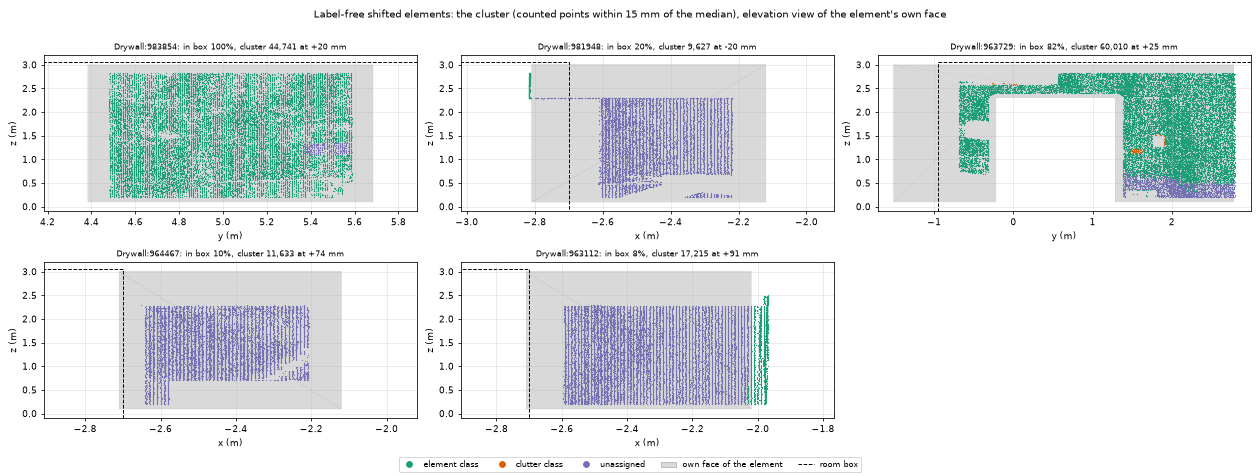

In [12]:
# 8b (1) The cause: which scan points form the cluster of each shifted element. The cluster is `cluster_of` (section 8): the counted points within TOL of the element's median offset, patch on.
# Per element: its scan classes, whether they are element-class, clutter-class or unassigned, how much of the cluster lies in the room box, and where on the element's face it lies.
XYZ: str = "xyz"


def elev_axes(e: Element) -> tuple[int, int]:
    # The two coordinates of the element's elevation view: along the wall and z for a wall (or a door, a window), x and y for a slab or a covering.
    a = thickness_axis(e)
    return (0, 1) if e.ifc_class in ("IfcSlab", "IfcCovering") else (1 - a, 2)


def cause_report(i: int, variant: str) -> None:
    e, use = elements[i], (use_all if variant == "no_labels" else use_oracle)
    cl, med = cluster_of(i, AP, use)
    u_ax, v_ax = elev_axes(e)
    n_counted = int(use[AP.points_of[i]].sum())
    cls = np.bincount(SCAN_CLASS[cl], minlength=len(CLASS_NAMES))
    by_class = ", ".join(f"{CLASS_NAMES[k]} {cls[k]:,}" for k in np.argsort(-cls, kind="stable") if cls[k])

    def pct(x: np.ndarray) -> np.ndarray:
        return np.percentile(x, [5, 95])

    def ext(ax: int) -> str:
        return f"{XYZ[ax]} {pct(P[cl, ax])[0]:.2f} to {pct(P[cl, ax])[1]:.2f} m (the element's own {e.vertices[:, ax].min():.2f} to {e.vertices[:, ax].max():.2f})"

    lab = cl[is_element_class[cl]]
    flag = " (excluded)" if EXC[i] else ""
    print(f"{META[e.global_id]['name'][-14:]} {e.ifc_class[3:]}{flag}: in box {AREA_IN_BOX[i]:.0%}, counted {n_counted:,}, cluster {len(cl):,} ({len(cl) / n_counted:.0%}) at {med * 1000:+.1f} mm; "
          f"verdicts no labels / labels: {BASE_P['no_labels'][i]['verdict']} / {BASE_P['oracle_labels'][i]['verdict']}; proxy {PROXY[i]['truth']}")
    print(f"    scan classes: {by_class}")
    print(f"    element class {is_element_class[cl].mean():.0%}, clutter class {is_clutter_class[cl].mean():.0%}, unassigned {(SCAN_CLASS[cl] == 0).mean():.0%}; inside the room box {in_box[cl].mean():.0%}")
    print(f"    5th-95th percentile: {ext(u_ax)}; {ext(v_ax)}" + ("" if v_ax == 2 else f"; {ext(2)}"))
    print(f"    the cluster's element-class points: {len(lab):,} ({len(lab) / len(cl):.0%}), median {np.median(AP_SIGNED[lab]) * 1000:+.1f} mm" if len(lab) else "    the cluster has no element-class point")


def fold_report(i: int) -> None:
    # Fold or displacement? A wall's far face measured against its near face reads as an offset of about the wall's thickness (03a's 9713/9790 diagnosis). The raw coordinates along the thickness axis
    # (not the offsets) say where the cluster sits against the two broad faces, and the wall side test's counts say how its points were placed.
    e, w = elements[i], A.side.walls[i]
    a = thickness_axis(e)
    lo, hi = float(e.vertices[:, a].min()), float(e.vertices[:, a].max())
    cl, _ = cluster_of(i, AP, use_all)
    patch = AP.points_of[i][use_all[AP.points_of[i]]]
    how = np.bincount(A.side.how[cl], minlength=4)

    def near(plane: float) -> float:
        return float((np.abs(P[cl, a] - plane) <= TOL).mean())

    print(f"    thickness axis {XYZ[a]}: broad faces at {lo:.3f} and {hi:.3f} m ({(hi - lo) * 1000:.0f} mm apart); raw {XYZ[a]} of the cluster, median {np.median(P[cl, a]):.3f} m; of the whole counted patch, median {np.median(P[patch, a]):.3f} m")
    print(f"    room-facing sides {w['sides']}, reference side {w['ref']:+d}; of {w['n_band']:,} band points: dropped {w['n_dropped']:,}, ambiguous {w['n_ambiguous']:,}, placed by plane {w['n_by_plane']:,}, overruled by plane {w['n_overruled']:,}; "
          f"the cluster was placed by own free space {how[HOW_OWN]:,}, plane {how[HOW_PLANE]:,}, ambiguous {how[HOW_AMBIGUOUS]:,}; share of the cluster within {TOL * 1000:.0f} mm of the plane at {lo:.3f}: {near(lo):.0%}, at {hi:.3f}: {near(hi):.0%}")


AP_SIGNED = A.signed.astype(np.float64)
LF_SHIFTED: list[int] = [i for i in range(len(elements)) if BASE_P["no_labels"][i]["verdict"] == "shifted"]
LAB_SHIFTED: list[int] = [i for i in range(len(elements)) if BASE_P["oracle_labels"][i]["verdict"] == "shifted"]
print(f"LABEL-FREE shifted elements ({len(LF_SHIFTED)}), patch on; their cluster, the points within {TOL * 1000:.0f} mm of the element's median:\n")
for i in LF_SHIFTED:
    cause_report(i, "no_labels")
    if elements[i].ifc_class == "IfcWallStandardCase":
        fold_report(i)
print(f"\nFor contrast: shifted WITH oracle labels ({len(LAB_SHIFTED)}); their cluster (oracle-class points only, so the groups are element class by construction):\n")
for i in LAB_SHIFTED:
    cause_report(i, "oracle_labels")

GROUP_COLOUR: dict[str, str] = {"element class": "#1b9e77", "clutter class": "#d95f02", "unassigned": "#7570b3"}
rng = np.random.default_rng(SEED)
n_panel = len(LF_SHIFTED)
if n_panel:
    n_cols = min(3, n_panel)
    fig, axs = plt.subplots(-(-n_panel // n_cols), n_cols, figsize=(6 * n_cols, 3.4 * -(-n_panel // n_cols)), squeeze=False)
    for ax in axs.ravel()[n_panel:]:
        ax.axis("off")
    for ax, i in zip(axs.ravel(), LF_SHIFTED):
        e = elements[i]
        cl, med = cluster_of(i, AP, use_all)
        u_ax, v_ax = elev_axes(e)
        tri = e.vertices[e.faces[OWN_TRI[e.global_id]]][:, :, [u_ax, v_ax]]
        ax.add_collection(PolyCollection(tri, facecolors="#d9d9d9", edgecolors="#bdbdbd", linewidths=0.2))
        ax.add_patch(plt.Rectangle((box_lo[u_ax], box_lo[v_ax]), box_hi[u_ax] - box_lo[u_ax], box_hi[v_ax] - box_lo[v_ax], fill=False, ec="k", ls="--", lw=1))
        shown = cl if len(cl) <= 20_000 else rng.choice(cl, 20_000, replace=False)
        for group, mask in (("element class", is_element_class[shown]), ("clutter class", is_clutter_class[shown]), ("unassigned", SCAN_CLASS[shown] == 0)):
            ax.scatter(P[shown[mask], u_ax], P[shown[mask], v_ax], s=1.5, c=GROUP_COLOUR[group], linewidths=0, rasterized=True)
        lo_all = np.concatenate([e.vertices[:, [u_ax, v_ax]], P[shown][:, [u_ax, v_ax]]]).min(0)
        hi_all = np.concatenate([e.vertices[:, [u_ax, v_ax]], P[shown][:, [u_ax, v_ax]]]).max(0)
        ax.set_xlim(lo_all[0] - 0.2, hi_all[0] + 0.2)
        ax.set_ylim(lo_all[1] - 0.2, hi_all[1] + 0.2)
        ax.set_xlabel(f"{XYZ[u_ax]} (m)")
        ax.set_ylabel(f"{XYZ[v_ax]} (m)")
        ax.grid(alpha=0.3)
        ax.set_title(f"{META[e.global_id]['name'][-14:]}: in box {AREA_IN_BOX[i]:.0%}, cluster {len(cl):,} at {med * 1000:+.0f} mm" + (" (excluded)" if EXC[i] else ""), fontsize=8)
    fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=6, color=c, label=g) for g, c in GROUP_COLOUR.items()] + [plt.Rectangle((0, 0), 1, 1, fc="#d9d9d9", ec="#bdbdbd", label="own face of the element"),
               plt.Line2D([], [], color="k", ls="--", lw=1, label="room box")], loc="lower center", ncol=5, fontsize=8)
    fig.suptitle("Label-free shifted elements: the cluster (counted points within 15 mm of the median), elevation view of the element's own face", fontsize=10)
    plt.tight_layout(rect=(0, 0.04, 1, 0.97))
    fig.savefig(OUT / "label_free_shifted_clusters.png", dpi=70)
    plt.close(fig)
    display(Image(filename=str(OUT / "label_free_shifted_clusters.png"), width=1050))


In [13]:
# 8b (2) The coverage of every element's cluster (patch on), both variants, for the elements with at least MIN_POINTS counted points.
EMPTY_FACE: list[str] = [elements[i].global_id for i in range(len(elements)) if not OWN_TRI[elements[i].global_id].any()]
COVER: dict[str, list[float]] = {v: [cluster_cover(i, AP, u) for i in range(len(elements))] for v, u in (("no_labels", use_all), ("oracle_labels", use_oracle))}
print(f"cluster = counted points within {TOL * 1000:.0f} mm of the element's median; coverage = share of the element's own-face cells ({COVER_CELL * 100:.0f} cm) holding a cluster point; elements without an own-face triangle: {len(EMPTY_FACE)}\n")
print(f"{'#':>2s} {'class':9s} {'name':16s} | {'no labels':13s} {'labels':13s} | {'proxy truth':11s} {'in box':>6s} | {'coverage no labels':>18s} {'coverage labels':>15s}")
for i, e in enumerate(elements):
    if np.isnan(COVER["no_labels"][i]) and np.isnan(COVER["oracle_labels"][i]):
        continue
    f = lambda c: "-" if np.isnan(c) else f"{c:.2f}"
    print(f"{i:2d} {e.ifc_class[3:12]:9s} {META[e.global_id]['name'][-16:]:16s} | {BASE_P['no_labels'][i]['verdict']:13s} {BASE_P['oracle_labels'][i]['verdict']:13s} | {PROXY[i]['truth']:11s} {AREA_IN_BOX[i]:6.0%} | "
          f"{f(COVER['no_labels'][i]):>18s} {f(COVER['oracle_labels'][i]):>15s}" + (" (excluded)" if EXC[i] else ""))


cluster = counted points within 15 mm of the element's median; coverage = share of the element's own-face cells (5 cm) holding a cluster point; elements without an own-face triangle: 0

 # class     name             | no labels     labels        | proxy truth in box | coverage no labels coverage labels
 0 Covering  de gesso:1426759 | not confirmed not confirmed | unclear        45% |               0.81            0.80
 1 Covering  de gesso:1431675 | not confirmed not confirmed | unclear         0% |               0.06            0.04 (excluded)
 2 Door      0 - EI30:1043337 | not confirmed not confirmed | unclear        80% |               0.50            0.40
 3 Slab      cm) Laje:1305914 | not confirmed not confirmed | no data        56% |               0.09               -
 5 Slab      o 60 X 60:911079 | not confirmed not confirmed | OK             11% |               0.68            0.60 (excluded)
 6 WallStand ) Drywall:983854 | shifted       shifted       | shifted       100% |  

In [14]:
# 8b (3) The sweep: the candidate rule at each MIN_COVER, on the patch-on baseline (both variants) and on the patch-on known-answer runs. A shifted verdict whose cluster covers less than MIN_COVER
# reads "not confirmed" (a cluster of NaN coverage cannot occur on a shifted verdict: it has at least MIN_POINTS counted points). Excluded elements are in no check.
MIN_COVERS: tuple[float, ...] = (0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50)
VARIANTS: tuple[str, ...] = ("no_labels", "oracle_labels")
OTHER: dict[str, str] = {"no_labels": "oracle_labels", "oracle_labels": "no_labels"}
NOT_EXC: list[int] = [i for i in range(len(elements)) if not EXC[i]]
ON: list[KnownAnswer] = [k for k in KNOWN if k["patch"] == "on"]
ONLY_LABEL_FREE: list[int] = [i for i in NOT_EXC if BASE_P["no_labels"][i]["verdict"] == "shifted" and BASE_P["oracle_labels"][i]["verdict"] != "shifted"]  # what the rule is for


def ruled(verdict: str, cover: float, min_cover: float) -> str:
    return "not confirmed" if verdict == "shifted" and cover < min_cover else verdict


COVER_RULE: dict[float, dict[str, bool]] = {}
SWEEP_ROWS: list[dict[str, object]] = []
print(f"label-free shifted that is not shifted with labels (non-excluded): {[META[elements[i].global_id]['name'][-6:] + ' cover ' + format(COVER['no_labels'][i], '.2f') for i in ONLY_LABEL_FREE]}\n")
for mc in MIN_COVERS:
    new = {v: [ruled(BASE_P[v][i]["verdict"], COVER[v][i], mc) for i in range(len(elements))] for v in VARIANTS}
    cnt = {v: {x: new[v].count(x) for x in ("OK", "shifted", "not confirmed")} for v in VARIANTS}
    cnt_ne = {v: {x: sum(new[v][i] == x for i in NOT_EXC) for x in ("OK", "shifted", "not confirmed")} for v in VARIANTS}
    flips = {v: [i for i in NOT_EXC if new[v][i] != BASE_P[v][i]["verdict"]] for v in VARIANTS}
    assert all(BASE_P[v][i]["verdict"] == "shifted" and new[v][i] == "not confirmed" for v in VARIANTS for i in flips[v]), "the rule changed something besides shifted -> not confirmed"
    print(f"MIN_COVER {mc:.2f}: OK / shifted / not confirmed, all {len(elements)} elements: no labels {cnt['no_labels']['OK']} / {cnt['no_labels']['shifted']} / {cnt['no_labels']['not confirmed']}, "
          f"labels {cnt['oracle_labels']['OK']} / {cnt['oracle_labels']['shifted']} / {cnt['oracle_labels']['not confirmed']}")
    for v in VARIANTS:
        for i in flips[v]:
            print(f"    {v:13s} {META[elements[i].global_id]['name'][-14:]} shifted -> not confirmed (cover {COVER[v][i]:.2f}); proxy truth {PROXY[i]['truth']}; verdict {OTHER[v].replace('_', ' ')}: {BASE_P[OTHER[v]][i]['verdict']}")
    known_flips = []
    for k in ON:
        after = ruled(k["actual"], k["cover"], mc)
        if after != k["actual"]:
            known_flips.append(dict(run=k["run"], variant=k["variant"], expected=k["expected"], was=k["actual"], now=after, was_right=k["right"], now_right=after == k["expected"], cover=k["cover"]))
    for kf in known_flips:
        print(f"    known answer {kf['run']:24s} {kf['variant']:13s} expected {kf['expected']:13s}: {kf['was']} -> {kf['now']} (cover {kf['cover']:.2f}); right {kf['was_right']} -> {kf['now_right']}")
    c_proxy = not any(PROXY[i]["truth"] == "shifted" for v in VARIANTS for i in flips[v])
    c_oracle = not any(BASE_P["oracle_labels"][i]["verdict"] == "shifted" for i in flips["no_labels"])
    c_known = not any(kf["expected"] == "shifted" for kf in known_flips)
    acceptable = c_proxy and c_oracle and c_known
    removes_all = all(COVER["no_labels"][i] < mc for i in ONLY_LABEL_FREE)
    COVER_RULE[mc] = dict(acceptable=acceptable, removes_all=removes_all, keeps_proxy_shifted=c_proxy, keeps_oracle_shifted=c_oracle, keeps_known_shifted=c_known)
    print(f"    acceptable on this room: {acceptable} (keeps proxy-shifted {c_proxy}; keeps shifted-with-labels {c_oracle}; keeps known-answer shifted {c_known}); "
          f"removes every label-free shifted that is not shifted with labels: {removes_all}" + (" (vacuous: there is none on this room)" if not ONLY_LABEL_FREE else ""))
    SWEEP_ROWS.append(dict(min_cover=mc, **{f"{v}_{x.replace(' ', '_')}": cnt[v][x] for v in VARIANTS for x in ("OK", "shifted", "not confirmed")},
                           **{f"{v}_removed": ";".join(META[elements[i].global_id]["name"][-6:] for i in flips[v]) for v in VARIANTS},
                           known_answer_flips=len(known_flips), known_answer_flips_wrong=sum(kf["was_right"] and not kf["now_right"] for kf in known_flips),
                           n_label_free_only=len(ONLY_LABEL_FREE), **COVER_RULE[mc]))
    print()
with open(OUT / "cover_sweep.csv", "w", newline="") as f:
    w = csv.DictWriter(f, list(SWEEP_ROWS[0]))
    w.writeheader()
    w.writerows(SWEEP_ROWS)
print("wrote", OUT / "cover_sweep.csv")


label-free shifted that is not shifted with labels (non-excluded): ['981948 cover 0.43', '964467 cover 0.44', '963112 cover 0.62']

MIN_COVER 0.00: OK / shifted / not confirmed, all 30 elements: no labels 1 / 5 / 24, labels 1 / 2 / 27
    acceptable on this room: True (keeps proxy-shifted True; keeps shifted-with-labels True; keeps known-answer shifted True); removes every label-free shifted that is not shifted with labels: False

MIN_COVER 0.05: OK / shifted / not confirmed, all 30 elements: no labels 1 / 5 / 24, labels 1 / 2 / 27
    acceptable on this room: True (keeps proxy-shifted True; keeps shifted-with-labels True; keeps known-answer shifted True); removes every label-free shifted that is not shifted with labels: False

MIN_COVER 0.10: OK / shifted / not confirmed, all 30 elements: no labels 1 / 5 / 24, labels 1 / 2 / 27
    acceptable on this room: True (keeps proxy-shifted True; keeps shifted-with-labels True; keeps known-answer shifted True); removes every label-free shifted

## 9. The room, top down

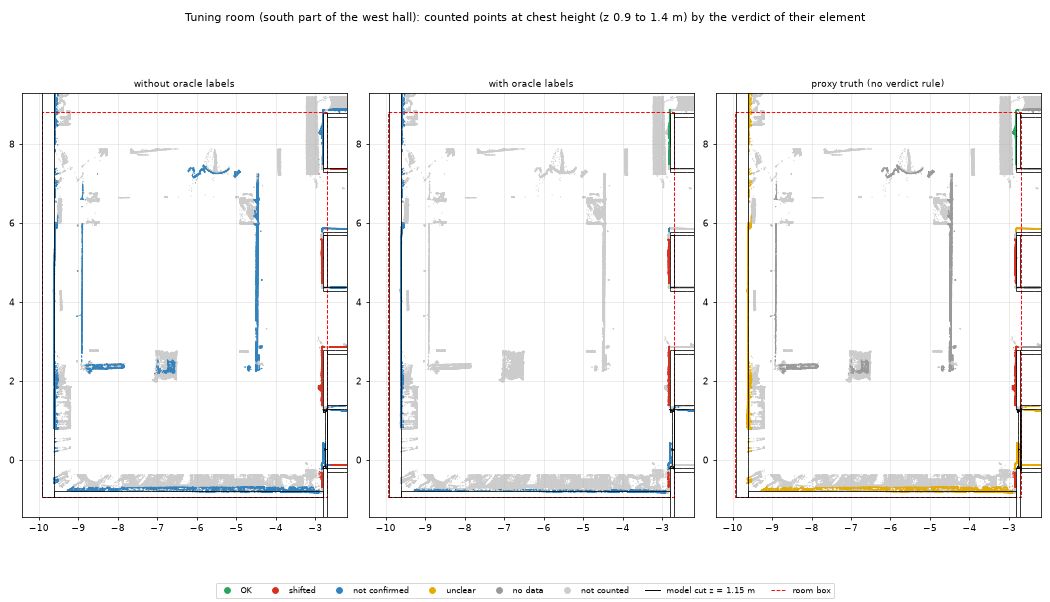

In [15]:
# Top-down view of the tuning room: counted scan points coloured by the verdict of their element (without labels, with labels) and by the proxy's truth; the model cut at chest height in black.
VERDICT_COLOUR = {"OK": "#2ca25f", "shifted": "#d7301f", "not confirmed": "#3182bd", "unclear": "#e6ab02", "no data": "#999999"}
GREY = np.array([0.80, 0.80, 0.80])
hex_rgb = lambda h: np.array([int(h[k:k + 2], 16) / 255 for k in (1, 3, 5)])


def section(els, axis, value):
    keep = [i for i in range(3) if i != axis]
    out = []
    for e in els:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t_ = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep] + t_[:, None] * (tri[idx, j][:, keep] - tri[idx, i][:, keep])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


rs = np.random.default_rng(SEED)
XLIM, YLIM = (box_lo[0] - 0.5, box_hi[0] + 0.5), (box_lo[1] - 0.5, box_hi[1] + 0.5)  # the plotted window: the room box and 0.5 m around it
slab = np.flatnonzero((P[:, 2] >= 0.9) & (P[:, 2] <= 1.4) & (P[:, 0] >= XLIM[0]) & (P[:, 0] <= XLIM[1]) & (P[:, 1] >= YLIM[0]) & (P[:, 1] <= YLIM[1]))
pick = np.sort(rs.choice(slab, min(150_000, len(slab)), replace=False))
owner = np.full(len(P), -1)
for i, idx in enumerate(A.points_of):
    owner[idx] = i
cuts = section(elements, 2, 1.15)
fig, axs = plt.subplots(1, 3, figsize=(15, 8.6))
for ax, (title, colour_of, use) in zip(axs, (("without oracle labels", lambda i: BASE["no_labels"][i]["verdict"], use_all), ("with oracle labels", lambda i: BASE["oracle_labels"][i]["verdict"], use_oracle),
                                             ("proxy truth (no verdict rule)", lambda i: PROXY[i]["truth"], use_all))):
    element_colour = np.array([hex_rgb(VERDICT_COLOUR[colour_of(i)]) for i in range(len(elements))])
    coloured = (owner[pick] >= 0) & use[pick]
    colour = np.where(coloured[:, None], element_colour[np.maximum(owner[pick], 0)], GREY)
    order = np.argsort(coloured, kind="stable")
    ax.scatter(P[pick[order], 0], P[pick[order], 1], s=1.2, c=colour[order], linewidths=0, rasterized=True)
    ax.add_collection(LineCollection(cuts, colors="k", linewidths=0.8))
    ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title, fontsize=9)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=6, color=c, label=v) for v, c in VERDICT_COLOUR.items()] + [plt.Line2D([], [], marker="o", ls="", ms=6, color=GREY, label="not counted"),
           plt.Line2D([], [], color="k", lw=1, label="model cut z = 1.15 m"), plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")], loc="lower center", ncol=8, fontsize=8)
fig.suptitle("Tuning room (south part of the west hall): counted points at chest height (z 0.9 to 1.4 m) by the verdict of their element")
plt.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(OUT / "verdicts_top_down.png", dpi=70)
plt.close(fig)
display(Image(filename=str(OUT / "verdicts_top_down.png"), width=1050))


## 10. Outputs

`proxy_truth.csv`, `diagnosis_no_labels.csv`, `patch_effect.csv`, `known_answers.csv`, `verdicts_{no_labels,oracle_labels}.csv`, `verdicts_top_down.png` in `outputs/03c/` (this room's folder, gitignored).

In [16]:
# Outputs (gitignored): the proxy, the diagnosis, the what-if, and the known answers, one CSV each
def write_csv(name, fields, rows):
    with open(OUT / name, "w", newline="") as f:
        w = csv.DictWriter(f, fields, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})


write_csv("proxy_truth.csv", ["global_id", "name", "ifc_class", "verdict_no_labels", "verdict_oracle_labels", "truth", "n_oracle", "n_plain", "plane_mm", "in_plane"],
          [dict(PROXY[i], global_id=e.global_id, name=META[e.global_id]["name"], ifc_class=e.ifc_class, verdict_no_labels=BASE["no_labels"][i]["verdict"], verdict_oracle_labels=BASE["oracle_labels"][i]["verdict"])
           for i, e in enumerate(elements)])
write_csv("diagnosis_no_labels.csv", ["global_id", "name", "n", "share", "fail_front", "fail_behind", "fail_element_class", "fail_clutter_class", "fail_unassigned", "fail_outside_box", "past_edge", "fail_past_edge", "fail_beyond_50mm", "share_without_past_edge",
                                      "share_without_clutter", "share_without_unassigned", "share_oracle", "share_trend_removed", "slope_u_mm_per_m", "slope_v_mm_per_m", "median_failing_mm"],
          [dict(d, global_id=elements[i].global_id, name=META[elements[i].global_id]["name"], slope_u_mm_per_m=d["slope_mm_per_m"][0], slope_v_mm_per_m=d["slope_mm_per_m"][1]) for i, d in DIAG.items()])
write_csv("patch_effect.csv", ["global_id", "name", "excluded", "truth", "verdict_off", "share_off", "points_off", "verdict_on", "share_on", "points_on", "labels_off", "labels_on"],
          [dict(global_id=e.global_id, name=META[e.global_id]["name"], excluded=EXC[i], truth=PROXY[i]["truth"], verdict_off=BASE["no_labels"][i]["verdict"], share_off=BASE["no_labels"][i]["share_within_tol"],
                points_off=BASE["no_labels"][i]["point_count"], verdict_on=BASE_P["no_labels"][i]["verdict"], share_on=BASE_P["no_labels"][i]["share_within_tol"], points_on=BASE_P["no_labels"][i]["point_count"],
                labels_off=BASE["oracle_labels"][i]["verdict"], labels_on=BASE_P["oracle_labels"][i]["verdict"]) for i, e in enumerate(elements)])
write_csv("known_answers.csv", ["run", "patch", "variant", "global_id", "name", "ifc_class", "change_mm", "expected", "actual", "right", "baseline", "pure_shift", "points", "median_mm", "median_change_mm", "share_within_tol",
                                "cover", "false_flags", "flagged_names", "changed_untouched", "changed_names"], [dict(k, global_id=elements[k["i"]].global_id) for k in KNOWN])
print("wrote", *sorted(p.name for p in OUT.iterdir()))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")


wrote cover_sweep.csv diagnosis_no_labels.csv known_answers.csv label_free_shifted_clusters.png patch_effect.csv proxy_truth.csv verdicts_no_labels.csv verdicts_oracle_labels.csv verdicts_top_down.png
peak RSS 1.17 GB, notebook run 3287 s


In [17]:
# The Answer's numbers, checked: a change in the logic that moves them fails here.
name_of = lambda i: META[elements[i].global_id]["name"][-6:]  # the number after the last colon
assert counts(BASE["no_labels"]) == {"OK": 0, "shifted": 5, "not confirmed": 25} and counts(BASE["oracle_labels"]) == {"OK": 1, "shifted": 2, "not confirmed": 27}
assert counts(BASE_P["no_labels"]) == {"OK": 1, "shifted": 5, "not confirmed": 24} and counts(BASE_P["oracle_labels"]) == {"OK": 1, "shifted": 2, "not confirmed": 27}
changed = {v: [name_of(i) for i in range(len(elements)) if not EXC[i] and BASE[v][i]["verdict"] != BASE_P[v][i]["verdict"]] for v in BASE}
assert changed == {"no_labels": ["982078"], "oracle_labels": []}, changed
i_982078 = next(i for i in range(len(elements)) if name_of(i) == "982078")
assert (BASE["no_labels"][i_982078]["point_count"], BASE_P["no_labels"][i_982078]["point_count"]) == (44100, 41162) and BASE_P["no_labels"][i_982078]["verdict"] == "OK"
assert len(scored) == 3 and sum(EXC) == 2 and sum(not e for e in EXC) == 28
assert OUTCOME == "PASS" and all(all(v.values()) for v in RULE.values())
print("the Answer's numbers hold")

# Issue #30 (section 8b): coverage of the walls in question and of the proxy-shifted walls, and the selection rule's outcome
cov = {name_of(i): round(COVER["no_labels"][i], 2) for i in range(len(elements))}
assert [cov[n] for n in ("981948", "964467", "963112", "963729", "983854")] == [0.43, 0.44, 0.62, 0.56, 0.80], cov
assert sorted(name_of(i) for i in ONLY_LABEL_FREE) == ["963112", "964467", "981948"]
assert all(r["acceptable"] and not r["removes_all"] for r in COVER_RULE.values())
print("the Answer's numbers hold (issue #30 too)")

the Answer's numbers hold
the Answer's numbers hold (issue #30 too)


## Answer

**The own-face patch, re-checked on the post-#23 logic, west hall.** #20 tuned the patch on 03a's logic before #23 (the scan cropped to the room box, a sliver rule). This notebook now runs the **post-#23 per-element-patch logic** (imported from `scan_vs_bim.compare`): each of the 30 elements is judged on its element patch (the scan points within 10 cm of its whole surface for which it is the nearest of the 135 element-class elements), the room box only selects the scope, and an element with no points reads "no points". With the patch **on** (03a's own-face parameters, which are #20's) this notebook's run reproduces integrated 03a on room B row for row (verdict, reason, point count, median, share within tolerance; asserted in section 3 and by `tests/test_notebook_03c.py`). The patch parameters are **#20's, unchanged** (edge allowance 1 cm; walls, slabs and coverings; a wall only if exactly one face is room-facing), thresholds fixed (`TOL` 15 mm, `MIN_FRAC_OK` 0.95), room B not used. The floor slab and one covering are in room B's list and are excluded from every score; 28 elements are scored.

**What changed against #20's pre-#23 results (patch off).** The frame is the same (0.366 degrees, 14.8 mm). Counts over the 30 elements (OK / shifted / not confirmed), without labels **0 / 2 / 28 -> 0 / 5 / 25**, with labels **1 / 2 / 27 -> 1 / 2 / 27**. The three walls that are shifted now without labels (`Drywall:981948`, `964467`, `963112`; 20, 10 and 8 % of their surface in the box) were "mostly outside the room box" or had too few points under the crop; each is now judged on its whole patch and reads one cluster at -21, +74 and +91 mm (85, 90 and 88 % within 15 mm of the median). With labels they have 600, 0 and 4,123 counted element-class points and stay not confirmed, because their points are mostly unannotated scan (section 8b); the proxy has no truth for two of them (no data) and calls the third unclear. The floor slab is judged on 3.6 M points (84 % within 15 mm without labels, 94 % with) instead of 0.4 M. The proxy is unchanged: it scores 3 elements (`982078` OK, `983854` and `963729` shifted).

**Patch off -> on (section 7).** Without labels **one non-excluded element changes: `Drywall:982078` goes from not confirmed (91.5 %, 44,100 counted points) to OK (97.8 %; 2,938 points past the wall's north end are no longer counted)**, which is what the proxy says it is; #20 saw the same element go 91.5 % -> 98 %. With labels nothing changes (`982078` is already OK, 95 % -> 99 %). Counts over the 30 elements, without labels 0 / 5 / 25 -> **1 / 5 / 24**, with labels 1 / 2 / 27 -> 1 / 2 / 27. Agreement with the proxy: without labels 2 of 3 -> 3 of 3, with labels 3 of 3 -> 3 of 3. The excluded slab goes from 83.6 % to 83.9 % without labels (still not confirmed).

**Known answers (section 8):** the moved wall `982078`, `983854` moved onto its own plane (+20 mm), the door and the hidden wall `982142` deleted. Without labels: changes beyond tolerance right 3 of 4 -> 3 of 4 (the 10 cm move reads not confirmed, 88 %, with and without the patch); expected OK right 1 of 3 -> **2 of 3** (the 1 cm move into the room: not confirmed 92 % -> OK 98 %; the unpatched rule's pure shift says not confirmed there). With labels 3 of 4 and 2 of 3, unchanged (that move reads OK 95 % -> 100 %). The 1 cm move away from the room (expected OK, plane 13.3 mm from the moved face) reads not confirmed in all four runs (65 -> 70 % and 67 -> 71 %): the 95 % rule cannot pass a plane that close to the edge. No untouched element is newly flagged shifted in any run (patch on or off). The first version of the patch (all walls) still gives its false OK (with labels, the 10 cm move reads OK, 98 %) and still turns the partition `982351` shifted at allowances of 0 and 1 cm (proxy unclear), the reasons for the one-sided rule.

**Acceptance rule (fixed in advance, section 8): PASS on this room.** (a) no false OK on a known-answer change beyond tolerance: PASS without and with labels (the 3 cm and 10 cm moves and the two deletions never read OK). (b) no new disagreement with the proxy: PASS without and with labels (no scored element goes from agreeing to disagreeing; the one verdict the patch changes is an agreement gained; no false OK or shifted against the proxy; no new OK or shifted that the proxy cannot judge). (c) no untouched element newly flagged shifted: PASS without and with labels (0 in 7 runs, patch on and off).

**Label-free shifted on little surface (issue #30, section 8b).** The three walls that are shifted only without labels (`981948`, `964467`, `963112`) are short walls (0.7 m) just past the box's east face. Their clusters (9,627, 11,633 and 17,215 points within 15 mm of the median) are **flat sheets of scanned surface, 89 to 100 % in the scan class unassigned, 0 % clutter class, 0 to 3 % inside the room box**, over the middle of each wall face (figure in 8b). They are **not a fold** onto the far face: 0 to 2 % of each cluster lies within 15 mm of either face plane; `964467` and `963112` are planes 73 and 91 mm in front of the +y face, `981948` 21 mm behind it. With labels they read not confirmed only because that area of the scan is not annotated, so labels cannot say whether these walls are displaced. The candidate rule (a label-free shifted needs its cluster to cover at least `MIN_COVER` of the element's own face, 5 cm cells) does **not** separate them: they cover 0.43, 0.44 and 0.62 of their faces, the proxy-shifted `963729` 0.56 (`983854` 0.80). Every swept value up to 0.50 is acceptable, but none removes all three; 0.50 removes two and keeps `963112`, and removing it would need more than 0.62, which removes `963729`. Room A has no such wall (all three label-free shifted walls are shifted with labels too), so it adds no evidence. A cut on the cluster's share inside the room box fails as well: room A's proxy-shifted `962532` has 0 % of its cluster in the box. **Decision (the selection rule fixed in 8b, confirmed by the owner): the verdict rule is kept as is.** The three verdicts stand as label-free shifted that nothing in this notebook confirms or refutes; whether the walls are displaced is a question for a look at the scan (the hand check), not for a threshold.

**Doubts.** The evidence is thin: one scored element changes verdict (`982078`), the proxy scores 3 of 28 elements, and the 1 cm move test is the same wall. Rule (c) is zero partly because `981948`, which #20 saw flagged in its 10 cm run, is now shifted in the baseline already (so not "newly" flagged). The three new label-free shifted verdicts above are a property of the post-#23 logic that the patch does not touch. The long brick walls, the door, the ceiling coverings and the windows are not changed by the patch.
